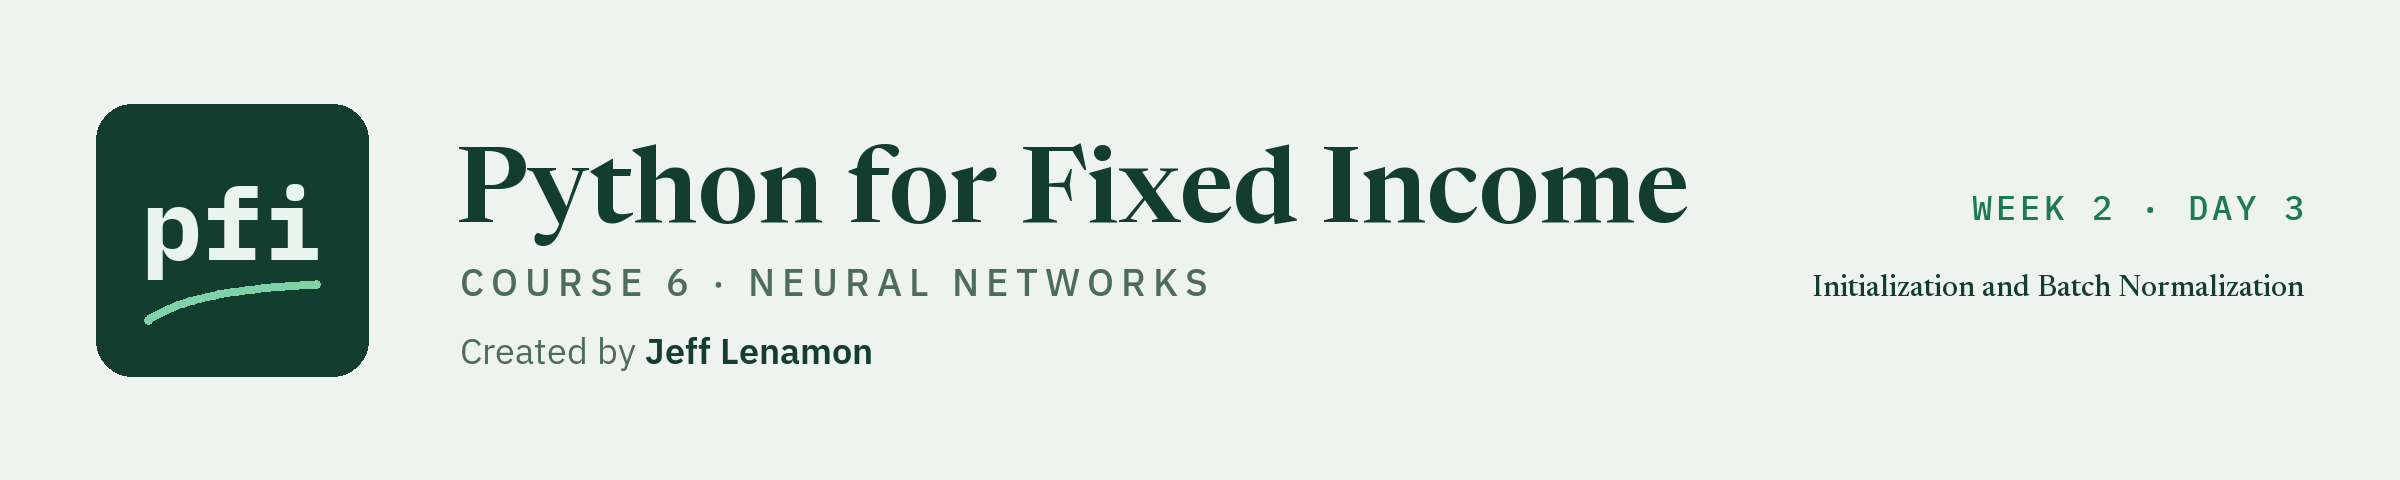

# Initialization and Batch Normalization

Week 2, Day 3. Where a network starts and how its layers' outputs are kept in range decide whether a deep network fits at all. Today: Keras's starting weights, why a start of zeros fails, vanishing gradients in a deep sigmoid network, and batch normalization by hand, in training and at scoring time.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course6_neural_networks/week2/day3/08_initialization_and_batch_normalization.ipynb)

Day 7 changed how each step moves the weights. Today is about two things that come before and between the steps: **where the weights start**, and what a **batch-normalization layer** does to the numbers passed from one layer to the next. Both matter little in the two-layer networks of week 1. They matter a great deal in a deep one, so today's networks have six hidden layers.

**The card rules, as on every card day in this course.**

* **The data is real.** `credit_card_default.csv` holds 30,000 credit card accounts in Taiwan in 2005, and consumer credit there differs from US credit. Nothing here describes any other market.
* **People's attributes are never features.** `SEX`, `EDUCATION`, `MARRIAGE`, and `AGE` are not used by any model, and no output is grouped by them. Every network uses the other 19 columns.
* **Course 4's split, rebuilt.** 18,000 training rows (14,400 to fit and 3,600 to stop or choose), 6,000 validation rows that report once, and Course 4's 6,000 test rows closed by day 1's test-row rule.
* **A model's output is described, never acted on.** A network's output is the model probability of default in this file, or a flag at a threshold; a network fitted with class weights gives the model's score. No output of either kind is a credit decision for any person.

Today you will:

1. Read what a Keras layer starts from: Glorot uniform by default, He normal on request.
2. See why a start of all zeros leaves every hidden unit a copy of the others.
3. Measure vanishing gradients in a deep sigmoid network (`gradient_norms`), and how ReLU with He normal evens them.
4. Do batch normalization by hand (`batch_norm_by_hand`) and check it against the Keras layer.
5. Fit four deep networks one setting at a time and choose on the stopping rows.
6. See what batch normalization uses at scoring time, and why one account's output never depends on the others scored with it.
7. Score the chosen network once on the validation rows.

Q. Set up today's work folder: TensorFlow's settings, the thread settings, the seed, the card file, and the modules as day 7 left them.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course6_neural_networks/requirements.txt
NEEDED = {
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [2]:
# today's setup: the TensorFlow and thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# TensorFlow writes start-up notices to stderr: these three lines must run before TensorFlow is imported
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, TensorFlow, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("tensorflow", "tensorflow"), ("keras", "keras"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

# one thread for TensorFlow too, set before TensorFlow runs anything
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
# TensorFlow's own Python notices are turned down to errors; on Windows the one it writes is that it has no GPU
# support there (day 1 explains it)
tf.get_logger().setLevel("ERROR")
# where TensorFlow has a deterministic version of an operation, use it
tf.config.experimental.enable_op_determinism()

# the versions the saved outputs of this notebook came from (course6_neural_networks/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "tensorflow": "2.21.0", "keras": "3.15.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42
# Keras's seed sets Python's, numpy's, and TensorFlow's random generators at once
keras.utils.set_random_seed(SEED)

# the kinds of device TensorFlow can use on this machine
devices = sorted({device.device_type for device in tf.config.list_physical_devices()})
print(f"Devices TensorFlow can use: {', '.join(devices)}")

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course6_08_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["credit_card_default.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, tensorflow 2.21.0, keras 3.15.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Devices TensorFlow can use: CPU
Work folder: pfi_course6_08__lszp351, in your temp folder
Data files from the data folder of the course repo: credit_card_default.csv
SEED = 42


* The setup cell is the same in every Course 6 notebook; day 1 explains each line.

Q. Write `mlkit.py`, Course 4's complete module, and `ensemblekit.py`, Course 5's complete module, both unchanged. `netkit` imports them.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)


from sklearn.base import BaseEstimator, TransformerMixin  # what makes a class a scikit-learn transformer
from sklearn.utils.validation import check_is_fitted  # stops a transformer used before fit


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """A ratio of two columns that is never infinite: missing where the denominator is 0 or either side is missing.

    Inputs: numerator, denominator, two Series with the same row labels.
    Output: numerator / denominator as floats, with NaN where the denominator is 0 or either value is missing.
    Convention: a model that handles missing values (or an imputer inside a pipeline) then deals with those rows;
    an infinity would break most estimators.
    Excel: =IF(OR(B2=0,B2="",A2=""),NA(),A2/B2), where =A2/B2 alone gives #DIV/0!.
    Raises ValueError if the two Series do not have the same row labels.
    """
    if not numerator.index.equals(denominator.index):
        raise ValueError("numerator and denominator must have the same row labels")
    defined = denominator.ne(0) & numerator.notna() & denominator.notna()
    # divide only where the ratio is defined; every other row stays NaN
    return numerator.astype(float).div(denominator.astype(float).where(defined)).where(defined)


class ClipToTraining(TransformerMixin, BaseEstimator):
    """Clip each column to bounds learned from the rows it is fitted on (by default the 1st and 99th percentiles).

    Inside a pipeline, fit sees only each fold's training rows, so the bounds never come from held-out rows.
    Parameters: lower, upper, the quantiles (0 <= lower < upper <= 1).
    Fitted attributes: lower_, upper_, one bound per column (numpy.nanquantile, linear, missing values ignored);
    n_features_in_; feature_names_in_ when fitted on a DataFrame.
    transform returns a float array; a missing value stays missing.
    Excel: =PERCENTILE.INC(training_range,0.01) and 0.99 give the bounds; =MIN(MAX(x,low),high) clips.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        if not 0 <= self.lower < self.upper <= 1:
            raise ValueError(f"need 0 <= lower < upper <= 1, not {self.lower}, {self.upper}")
        values = np.asarray(X, dtype=float)
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = values.shape[1]
        # each column's bounds, from these rows only
        self.lower_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        values = np.asarray(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError(f"X has {values.shape[1]} columns, the transformer was fitted on {self.n_features_in_}")
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["lower_", "upper_"])
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


def class_counts_after(sampler, X, y) -> pd.Series:
    """How many rows of each class a resampler leaves: for showing what a sampler does.

    Inputs: sampler, an imbalanced-learn sampler such as SMOTE(random_state=42); X, y, rows with no missing value.
    Output: the count of each class after sampler.fit_resample(X, y), indexed by class.
    Convention: a demonstration only. Rows a model is scored on are never resampled; resampling belongs inside an
    imblearn pipeline, where cross-validation resamples each fold's training rows only.
    """
    _, y_resampled = sampler.fit_resample(X, y)
    return pd.Series(y_resampled).value_counts().sort_index()


def prior_correction(score, fitted_rate: float, true_rate: float) -> np.ndarray:
    """Move a score from a model fitted at one outcome rate back to the rate of the real rows.

    Inputs: score, the model's outputs (between 0 and 1); fitted_rate, the outcome rate of the rows the model was
    fitted on (0.5 after SMOTE to balance); true_rate, the outcome rate of the real training rows.
    Output: each score's odds multiplied by k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate)),
    turned back into a number between 0 and 1: s * k / (s * k + 1 - s).
    Convention: a closed form that assumes resampling changed only the class shares; it leaves the ranking of rows
    unchanged. Equal rates give the score back.
    Excel: k in one cell, =(t/(1-t))/(f/(1-f)), then =p*k/(p*k+1-p) filled down.
    Raises ValueError if a rate is not strictly between 0 and 1 or a score is outside [0, 1].
    """
    for name, rate in (("fitted_rate", fitted_rate), ("true_rate", true_rate)):
        if not 0 < rate < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1, not {rate}")
    s = np.asarray(score, dtype=float)
    if s.size == 0 or (s < 0).any() or (s > 1).any():
        raise ValueError("score must be non-empty and between 0 and 1")
    # the factor that moves odds from the fitted rate to the true rate
    k = (true_rate / (1 - true_rate)) / (fitted_rate / (1 - fitted_rate))
    return s * k / (s * k + 1 - s)


import re  # whole-word search

# words that turn a description of a model into a claim about causes; a reminder, not a proof
EXPLANATION_WORDS = ["cause", "causes", "caused", "driver", "drivers", "drives", "reason", "reasons", "because"]


def shap_table(shap_values, top: int | None = None) -> pd.DataFrame:
    """Mean absolute SHAP value per feature, largest first.

    Inputs: shap_values, a shap.Explanation for one output (rows by features), for example
    shap.TreeExplainer(model)(X); top, how many features to keep (all if None).
    Output: a DataFrame indexed by feature with columns mean_abs_shap (the average size of the feature's
    contribution to the model's log-odds, in log-odds) and rank (1 = largest).
    Convention: a SHAP value describes how the model's output for a row splits across features; it is not the
    effect of changing a feature and not a cause.
    Excel: =AVERAGE(ABS(column)) on a pasted column of SHAP values.
    Raises ValueError if the values are not one row per observation and one column per feature.
    """
    values = np.asarray(shap_values.values, dtype=float)
    if values.ndim != 2 or values.shape[1] != len(shap_values.feature_names):
        raise ValueError(f"expected rows by features, got shape {values.shape}")
    table = pd.DataFrame({"mean_abs_shap": np.abs(values).mean(axis=0)},
                         index=pd.Index(shap_values.feature_names, name="feature"))
    table = table.sort_values("mean_abs_shap", ascending=False, kind="stable")
    table["rank"] = np.arange(1, len(table) + 1)
    return table if top is None else table.head(top)


def assert_additive(shap_values, raw_score, tol: float = 1e-9) -> None:
    """Stop unless each row's SHAP values add up to the model's raw output (log-odds).

    Inputs: shap_values, a shap.Explanation for one output; raw_score, the model's log-odds for the same rows
    (LightGBM: predict(X, raw_score=True); XGBoost: predict(X, output_margin=True)); tol, the largest gap allowed
    (1e-9 for LightGBM; 1e-5 for XGBoost, which computes in float32).
    Output: None when base value + the row's SHAP values equals raw_score in every row within tol.
    Convention: the contributions add up in log-odds, not in probability; mlkit.logistic_probability turns the sum
    into the model's probability.
    Raises AssertionError naming the largest gap and its row position, and ValueError on lengths that differ.
    """
    values = np.asarray(shap_values.values, dtype=float)
    raw = np.asarray(raw_score, dtype=float)
    if values.ndim != 2 or values.shape[0] != raw.size:
        raise ValueError(f"shap_values has {values.shape[0]} rows and raw_score {raw.size}")
    # base value plus the row's contributions, against the model's own log-odds
    gaps = np.abs(np.asarray(shap_values.base_values, dtype=float) + values.sum(axis=1) - raw)
    worst = int(np.argmax(gaps))
    if gaps[worst] > tol:
        raise AssertionError(f"SHAP values do not add up to raw_score: largest gap {gaps[worst]:.3g} at row "
                             f"position {worst} (tolerance {tol:g}); raw_score must be log-odds, not a probability")


def assert_described(text: str) -> None:
    """Stop if a written description uses a forecast word or a cause word.

    Input: text, a description of what a model shows.
    Output: None if the text passes mlkit.assert_descriptive and holds no word of EXPLANATION_WORDS as a whole word,
    in any case.
    Convention: the lists are a reminder, not a proof. "because" is on the list so the writer looks again at every
    causal sentence; a description that needs it rewrites the sentence.
    Raises ValueError naming the words found.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in EXPLANATION_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses cause or explanation words: {found}")

Writing ensemblekit.py


Q. Write `netkit.py` and `test_netkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile netkit.py
"""netkit: the pieces of neural networks that Keras leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 6: Neural Networks. It imports mlkit (Course 4's module) and
ensemblekit (Course 5's module) and never changes either.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one. Every function that builds a Keras model calls
  keras.utils.set_random_seed(seed) first, so a model's numbers do not depend on what ran before it.
- Keras runs quietly: verbose=0 on every fit, predict, and evaluate.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 6 never scores a row that an earlier course used as a test row: rows come from ensemblekit.course4_*_rows.
- Rows that fit a network, rows that stop or choose, and rows that report a result are kept apart. A scaler is
  fitted on the fit rows only (fit_arrays).
- Changes and errors on the Treasury curve are in basis points (bp).
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import os

# TensorFlow reads these when it is imported. setdefault keeps whatever a notebook's setup cell already set, and
# quiets TensorFlow's start-up notices when the tests run from PowerShell.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
import tensorflow as tf  # tensors and automatic gradients
import keras  # networks: layers, optimizers, losses

import ensemblekit  # Course 5's module: the card, benchmark, and Polish rows, stopping rows, mae_bp
import mlkit  # Course 4's module: folds, thresholds, metrics, and the no-leak checks


def _labels_and_scores(y, p) -> tuple[np.ndarray, np.ndarray]:
    """y and p as float64 arrays of the same length, y holding only 0 and 1; raises ValueError otherwise."""
    labels = np.asarray(y, dtype=float).ravel()
    scores = np.asarray(p, dtype=float).ravel()
    if labels.size == 0 or labels.size != scores.size:
        raise ValueError(f"y and p must be non-empty and the same length, not {labels.size} and {scores.size}")
    if not np.isin(labels, (0.0, 1.0)).all():
        raise ValueError("y must hold only 0 and 1")
    return labels, scores


def mean_log_loss(y, p, epsilon: float = 1e-7) -> float:
    """The mean log loss (binary cross-entropy) of outputs p for outcomes y.

    Inputs: y, outcomes (0 or 1); p, the model's outputs, between 0 and 1, the same length; epsilon, how far from 0
    and 1 each output is clipped.
    Output: mean of -(y ln p + (1 - y) ln(1 - p)), with p clipped to [epsilon, 1 - epsilon] as Keras clips (its
    default epsilon is 1e-7). Equals sklearn.metrics.log_loss within 1e-12 when no output is clipped.
    Excel: =-(B2*LN(C2)+(1-B2)*LN(1-C2)) filled down, then =AVERAGE of the column.
    Raises ValueError on lengths that differ or labels other than 0 and 1.
    """
    labels, scores = _labels_and_scores(y, p)
    # keep every output inside (0, 1), so no logarithm is of 0
    clipped = np.clip(scores, epsilon, 1 - epsilon)
    return float(np.mean(-(labels * np.log(clipped) + (1 - labels) * np.log(1 - clipped))))


def _neuron_inputs(w, b: float, X, y) -> tuple[np.ndarray, float, np.ndarray, np.ndarray]:
    """w, X, y as float64 arrays that line up with each other; raises ValueError otherwise."""
    weights = np.asarray(w, dtype=float).ravel()
    rows = np.asarray(X, dtype=float)
    if rows.ndim != 2 or rows.shape[0] == 0:
        raise ValueError(f"X must be a non-empty 2-D array of rows by columns, not shape {rows.shape}")
    if rows.shape[1] != weights.size:
        raise ValueError(f"X has {rows.shape[1]} columns but w has {weights.size} weights")
    labels, _ = _labels_and_scores(y, np.zeros(rows.shape[0]))
    return weights, float(b), rows, labels


def log_loss_gradient(w, b: float, X, y) -> tuple[np.ndarray, float]:
    """The gradient of the mean log loss of one sigmoid neuron, worked by hand.

    Inputs: w, one weight per column of X; b, the intercept; X, the rows (rows by columns); y, the outcomes (0 or 1).
    Output: (gradient for the weights, gradient for the intercept), in float64: ((p - y) @ X / n, mean(p - y)),
    where p = 1 / (1 + exp(-(X @ w + b))) and n is the number of rows.
    Convention: the gradient is averaged over the rows, as Keras averages the loss over a batch. Equals
    tf.GradientTape on float64 tensors within 1e-12.
    Excel: =SUMPRODUCT(C2:C18001-B2:B18001,A2:A18001)/ROWS(A2:A18001) for a weight and
    =SUMPRODUCT(C2:C18001-B2:B18001)/ROWS(A2:A18001) for the intercept.
    Raises ValueError if the shapes do not line up or y holds labels other than 0 and 1.
    """
    weights, intercept, rows, labels = _neuron_inputs(w, b, X, y)
    # the neuron's output for each row, then how far it is from the outcome
    p = 1 / (1 + np.exp(-(rows @ weights + intercept)))
    error = p - labels
    return error @ rows / rows.shape[0], float(error.mean())


def gradient_step(w, b: float, X, y, learning_rate: float) -> tuple[np.ndarray, float]:
    """One full-batch step of gradient descent for one sigmoid neuron.

    Inputs: w, b, X, y as log_loss_gradient; learning_rate, the size of the step (above 0).
    Output: (w - learning_rate * gradient for the weights, b - learning_rate * gradient for the intercept).
    Convention: a learning rate that is too large makes the loss rise instead of fall.
    Excel: =$H$2-$H$5*$H$7 for each weight, with the gradient in its own cell.
    Raises ValueError unless learning_rate > 0, and as log_loss_gradient.
    """
    if not learning_rate > 0:
        raise ValueError(f"learning_rate must be above 0, not {learning_rate}")
    gradient_w, gradient_b = log_loss_gradient(w, b, X, y)
    return np.asarray(w, dtype=float).ravel() - learning_rate * gradient_w, float(b) - learning_rate * gradient_b


from sklearn.base import clone  # a fresh, unfitted copy of a transformer


def fit_arrays(transformer, X_fit, *others) -> tuple:
    """Fit a scaler (or any scikit-learn transformer) on the fit rows only, then transform every set of rows.

    Inputs: transformer, an unfitted scikit-learn transformer, for example StandardScaler(), a ColumnTransformer,
    or a Pipeline of an imputer and a QuantileTransformer; X_fit, the rows the network is fitted on; others, any
    other sets of rows (stopping rows, validation rows, a held-out fold).
    Output: (fitted, A_fit, *A_others): a clone of transformer fitted on X_fit only, and float32 arrays of X_fit and
    of each of others transformed by that fitted copy.
    Convention: this is the course's one way to scale rows for a network. The rows in others are never seen by the
    fit, so their statistics cannot leak into the scaling.
    Raises ValueError if X_fit is empty.
    """
    if len(X_fit) == 0:
        raise ValueError("X_fit is empty")
    # a clone, so the transformer passed in stays unfitted and can be used again
    fitted = clone(transformer).fit(X_fit)
    arrays = [np.asarray(fitted.transform(rows), dtype="float32") for rows in (X_fit, *others)]
    return (fitted, *arrays)


def neuron_coefficients(model, names: list[str]) -> pd.Series:
    """The intercept and weights of a network that is one neuron.

    Inputs: model, a Keras model with exactly one Dense layer of one unit; names, the input columns' names.
    Output: a Series indexed intercept, then names, in the model's input units (scaled inputs give weights per
    standard deviation). With a sigmoid output these are log-odds coefficients, as a logistic regression's.
    Raises ValueError if the model has another Dense layer, the layer has more than one unit, or names has the
    wrong length.
    """
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    if len(dense) != 1 or dense[0].units != 1:
        raise ValueError("the model must have exactly one Dense layer with one unit")
    kernel, bias = dense[0].get_weights()
    if len(names) != kernel.shape[0]:
        raise ValueError(f"the layer has {kernel.shape[0]} inputs but {len(names)} names were given")
    return pd.Series(np.concatenate([bias, kernel[:, 0]]).astype(float), index=["intercept", *names])


ACTIVATIONS = {
    "linear": lambda z: z,
    "relu": lambda z: np.maximum(0.0, z),
    "tanh": np.tanh,
    "sigmoid": lambda z: 1 / (1 + np.exp(-z)),
}


def forward_pass(model, A) -> np.ndarray:
    """A dense network's output computed with numpy, layer by layer, in float64.

    Inputs: model, a Keras Sequential model of Dense layers (activations linear, relu, tanh, or sigmoid) and
    Dropout layers; A, the scaled input rows (rows by inputs).
    Output: the model's output for each row, shaped as model.predict's (rows by output units). Each Dense layer
    computes activation(inputs @ kernel + bias); Dropout passes its inputs through, as at scoring time.
    Convention: equals model.predict(A, verbose=0) within 1e-5 (Keras computes in float32).
    Excel: one unit is =MAX(0,SUMPRODUCT(inputs,weights)+bias) for ReLU, =TANH(...) for tanh,
    =1/(1+EXP(-(...))) for sigmoid.
    Raises ValueError on any other layer or activation, or rows of the wrong width.
    """
    values = np.asarray(A, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError(f"A must be a non-empty 2-D array of rows by inputs, not shape {values.shape}")
    for layer in model.layers:
        if isinstance(layer, keras.layers.Dropout):
            continue  # at scoring time dropout changes nothing
        if not isinstance(layer, keras.layers.Dense):
            raise ValueError(f"forward_pass handles Dense and Dropout layers only, not {type(layer).__name__}")
        activation = layer.get_config()["activation"]
        if activation not in ACTIVATIONS:
            raise ValueError(f"forward_pass handles {sorted(ACTIVATIONS)} activations only, not {activation!r}")
        kernel, bias = (w.astype(float) for w in layer.get_weights())
        if values.shape[1] != kernel.shape[0]:
            raise ValueError(f"layer {layer.name} expects {kernel.shape[0]} inputs, not {values.shape[1]}")
        values = ACTIVATIONS[activation](values @ kernel + bias)
    return values


def parameter_count(layer_sizes: list[int]) -> int:
    """How many weights and biases a stack of dense layers has.

    Input: layer_sizes, the number of inputs first, then each layer's units, the output layer last, for example
    [19, 64, 32, 1].
    Output: the sum of a * b + b over consecutive sizes a, b (a kernel of a by b weights and b biases per layer).
    Convention: equals model.count_params() for a Sequential model of Dense layers.
    Excel: =19*64+64 for one layer, added up over the layers.
    Raises ValueError on fewer than two sizes or a size below 1.
    """
    sizes = list(layer_sizes)
    if len(sizes) < 2 or min(sizes) < 1:
        raise ValueError(f"need at least two sizes, each at least 1, not {sizes}")
    return int(sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:])))


import math  # ceil for whole steps


def steps_per_epoch(n_rows: int, batch_size: int) -> int:
    """How many gradient steps one epoch takes: one per batch, the last batch possibly smaller.

    Inputs: n_rows, the rows the network is fitted on; batch_size, the rows per step.
    Output: ceil(n_rows / batch_size), for example 225 for 14,400 rows at batch 64.
    Excel: =ROUNDUP(14400/64,0).
    Raises ValueError unless both are at least 1.
    """
    if n_rows < 1 or batch_size < 1:
        raise ValueError(f"n_rows and batch_size must both be at least 1, not {n_rows} and {batch_size}")
    return math.ceil(n_rows / batch_size)


def history_table(history) -> pd.DataFrame:
    """The losses Keras recorded during fit, one row per epoch.

    Input: history, the object model.fit returns.
    Output: a DataFrame indexed epoch (from 1), one column per key of history.history, for example loss (the fit
    rows) and val_loss (the stopping rows).
    Raises ValueError if nothing was recorded.
    """
    if not history.history:
        raise ValueError("the history holds no recorded values")
    table = pd.DataFrame(history.history)
    table.index = pd.RangeIndex(1, len(table) + 1, name="epoch")
    return table


def best_epoch(history, monitor: str = "val_loss") -> int:
    """The epoch with the smallest value of monitor, counted from 1.

    Inputs: history, the object model.fit returns; monitor, the recorded value to read.
    Output: the first epoch (from 1) at which monitor is smallest; on a tie the earlier epoch.
    Convention: the stopping rule reads the stopping rows' loss (val_loss), never the training loss, which keeps
    falling as the network fits its own rows more closely.
    Excel: =MATCH(MIN(C2:C41),C2:C41,0) on a pasted loss column.
    Raises ValueError if monitor is not recorded.
    """
    if monitor not in history.history:
        raise ValueError(f"{monitor!r} is not recorded; recorded: {sorted(history.history)}")
    # argmin returns the first position of the smallest value
    return int(np.argmin(history.history[monitor])) + 1


from sklearn.metrics import average_precision_score, roc_auc_score  # scores from the network's outputs


def dense_classifier(n_inputs: int, units: tuple = (64, 32), activation: str = "relu", dropout: float = 0.0,
                     learning_rate: float = 1e-3, seed: int = 42) -> keras.Model:
    """A compiled dense network for a 0/1 outcome: the course's default classification network.

    Inputs: n_inputs, the number of input columns; units, the width of each hidden layer, first layer first;
    activation, the hidden layers' activation; dropout, the share of a hidden layer's outputs dropped in training
    (0 for none); learning_rate, Adam's step size; seed, the seed set before the weights are drawn.
    Output: keras.Sequential with keras.Input, one Dense layer per entry of units (named hidden_1, hidden_2, ...,
    each followed by Dropout(dropout), named dropout_1, ..., when dropout > 0), and Dense(1, activation="sigmoid")
    named output; compiled with Adam(learning_rate) and binary_crossentropy.
    Convention: keras.utils.set_random_seed(seed) runs first, so two builds start from the same weights.
    Raises ValueError on an empty units, a width below 1, or dropout outside [0, 1).
    """
    if len(units) == 0 or min(units) < 1:
        raise ValueError(f"units must hold at least one width, each at least 1, not {units}")
    if not 0 <= dropout < 1:
        raise ValueError(f"dropout must be at least 0 and below 1, not {dropout}")
    keras.utils.set_random_seed(seed)
    layers = [keras.Input(shape=(n_inputs,))]
    for i, width in enumerate(units, start=1):
        layers.append(keras.layers.Dense(width, activation=activation, name=f"hidden_{i}"))
        if dropout > 0:
            layers.append(keras.layers.Dropout(dropout, name=f"dropout_{i}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name="dense_classifier")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy")
    return model


def cv_network(build, transformer, X, y, cv=None, epochs: int = 200, batch_size: int = 64, patience: int = 10,
               class_weight=None) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a network: out-of-fold outputs, with early stopping on rows carved from each fold.

    Inputs: build, a function build(n_inputs) that returns a compiled model; transformer, an unfitted scaler or
    pipeline (fit_arrays fits a fresh clone per fold); X, y, the training rows (a DataFrame and a Series); cv, the
    splitter (default mlkit.cv_folds()); epochs, the most epochs; batch_size; patience, the epochs early stopping
    waits; class_weight, passed to fit (None for none).
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with roc_auc and average_precision on
    the held-out fold, best_epoch (from 1), and epochs_run. out_of_fold holds each row's output from the network
    that did not see it, in the order of X.
    Convention: per fold, the fold's training rows are split by ensemblekit.early_stopping_rows into fit rows and
    stopping rows; the transformer is fitted on the fit rows only; EarlyStopping(monitor="val_loss",
    patience=patience, restore_best_weights=True) watches the stopping rows. The held-out fold is never fitted,
    stopped, or scaled on (mlkit.assert_disjoint proves it). keras.utils.set_random_seed(42) runs before each
    fold's build. A class-weighted network's output is a score, not a probability.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds()
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        # stopping rows come from the fold's training rows, never from the held-out fold
        X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, y_fit.to_numpy("float32"), validation_data=(A_stop, y_stop.to_numpy("float32")),
                            epochs=epochs, batch_size=batch_size, class_weight=class_weight, callbacks=[stop],
                            verbose=0)
        output = model.predict(A_held, verbose=0).ravel()
        out_of_fold[held_out] = output
        rows[f"fold_{number}"] = {"roc_auc": roc_auc_score(y_held, output),
                                  "average_precision": average_precision_score(y_held, output),
                                  "best_epoch": best_epoch(history), "epochs_run": len(history.history["loss"])}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


from sklearn.model_selection import train_test_split  # a random fifth of a fold's training rows to stop on


def regression_losses(y_true, y_fitted, delta: float = 1.0) -> dict[str, float]:
    """Three regression losses by hand: mean squared error, mean absolute error, and the Huber loss.

    Inputs: y_true and y_fitted, the same length, in the target's unit; delta, where the Huber loss turns from
    squared to straight (in the target's unit, above 0).
    Output: {"mse", "mae", "huber"}. Huber is the mean of 0.5 e^2 where |e| <= delta and
    delta (|e| - 0.5 delta) elsewhere, so a large residual counts in proportion, not squared.
    Convention: equal to keras.losses.mean_squared_error, mean_absolute_error, and Huber(delta) within 1e-6.
    Excel: =SUMXMY2(a,b)/COUNT(a), =AVERAGE(ABS(a-b)), and =IF(ABS(e)<=d,0.5*e^2,d*(ABS(e)-0.5*d)) averaged.
    Raises ValueError on inputs that are empty or of different lengths, or delta not above 0.
    """
    actual = np.asarray(y_true, dtype=float).ravel()
    fitted = np.asarray(y_fitted, dtype=float).ravel()
    if actual.size == 0 or actual.size != fitted.size:
        raise ValueError(f"inputs must be non-empty and the same length, not {actual.size} and {fitted.size}")
    if not delta > 0:
        raise ValueError(f"delta must be above 0, not {delta}")
    error = actual - fitted
    size = np.abs(error)
    huber = np.where(size <= delta, 0.5 * error ** 2, delta * (size - 0.5 * delta))
    return {"mse": float(np.mean(error ** 2)), "mae": float(np.mean(size)), "huber": float(np.mean(huber))}


def cv_regressor(build, transformer, X, y, cv=None, epochs: int = 100, batch_size: int = 32,
                 patience: int = 10) -> tuple[pd.DataFrame, np.ndarray]:
    """Cross-validate a regression network: out-of-fold fitted values, in the target's own units.

    Inputs: build, a function build(n_inputs) that returns a compiled model with a linear output; transformer, an
    unfitted scaler or ColumnTransformer (fit_arrays fits a fresh clone per fold); X, y, the training rows (a
    DataFrame and a Series, for example log_oas); cv, the splitter (default mlkit.cv_folds("regression")); epochs,
    batch_size, patience as cv_network.
    Output: (table, out_of_fold). table has one row per fold (fold_1, ...) with mae and r2 on the held-out fold in
    the target's units (mlkit.regression_metrics) and best_epoch; out_of_fold holds each row's fitted value from
    the network that did not see it, in the order of X and in the target's units.
    Convention: per fold, a random fifth of the fold's training rows (seed 42) are the stopping rows; the target is
    standardized with the fit rows' mean and standard deviation (ddof=0) for fitting and turned back before anything
    is returned. For a log_oas target, ensemblekit.mae_bp(y, out_of_fold) gives the error in bp.
    Raises ValueError if X and y differ in length.
    """
    if len(X) != len(y) or len(X) == 0:
        raise ValueError(f"X and y must be non-empty and the same length, not {len(X)} and {len(y)}")
    folds = cv if cv is not None else mlkit.cv_folds("regression")
    out_of_fold = np.full(len(X), np.nan)
    rows = {}
    for number, (train, held_out) in enumerate(folds.split(X, y), start=1):
        X_train, y_train = X.iloc[train], y.iloc[train]
        X_held, y_held = X.iloc[held_out], y.iloc[held_out]
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
        mlkit.assert_disjoint(X_fit.index, X_held.index)
        mlkit.assert_disjoint(X_stop.index, X_held.index)
        _, A_fit, A_stop, A_held = fit_arrays(transformer, X_fit, X_stop, X_held)
        # the target in standard units of the fit rows, so the network's output layer starts near the right scale
        centre, spread = float(y_fit.mean()), float(y_fit.std(ddof=0))
        t_fit = ((y_fit.to_numpy(float) - centre) / spread).astype("float32")
        t_stop = ((y_stop.to_numpy(float) - centre) / spread).astype("float32")
        keras.utils.set_random_seed(42)
        model = build(A_fit.shape[1])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        history = model.fit(A_fit, t_fit, validation_data=(A_stop, t_stop), epochs=epochs, batch_size=batch_size,
                            callbacks=[stop], verbose=0)
        # turned back to the target's units before anything is scored or returned
        fitted = model.predict(A_held, verbose=0).ravel().astype(float) * spread + centre
        out_of_fold[held_out] = fitted
        metrics = mlkit.regression_metrics(y_held, fitted)
        rows[f"fold_{number}"] = {"mae": metrics["mae"], "r2": metrics["r2"], "best_epoch": best_epoch(history)}
    return pd.DataFrame.from_dict(rows, orient="index"), out_of_fold


def momentum_step(w, velocity, gradient, learning_rate: float, momentum: float) -> tuple[np.ndarray, np.ndarray]:
    """One step of gradient descent with momentum, as Keras's SGD optimizer takes it.

    Inputs: w, the weights; velocity, the velocity carried from the last step (zeros before the first); gradient,
    the loss gradient at w; learning_rate, above 0; momentum, from 0 (plain SGD) to below 1.
    Output: (new w, new velocity): velocity = momentum * velocity - learning_rate * gradient, then w + velocity.
    Convention: Keras 3's SGD update (read from its sgd.py, without Nesterov). Equals
    keras.optimizers.SGD(learning_rate, momentum) for two steps within 1e-6.
    Excel: =$B$1*C2-$B$2*D2 for the velocity, then =A2+E2.
    Raises ValueError on shapes that differ, learning_rate not above 0, or momentum outside [0, 1).
    """
    weights, carried, step = (np.asarray(a, dtype=float) for a in (w, velocity, gradient))
    if not weights.shape == carried.shape == step.shape:
        raise ValueError(f"w, velocity, gradient must have the same shape, not {weights.shape}, {carried.shape}, "
                         f"{step.shape}")
    if not learning_rate > 0 or not 0 <= momentum < 1:
        raise ValueError(f"need learning_rate > 0 and 0 <= momentum < 1, not {learning_rate} and {momentum}")
    carried = momentum * carried - learning_rate * step
    return weights + carried, carried


def adam_step(w, m, v, gradient, step: int, learning_rate: float = 1e-3, beta_1: float = 0.9, beta_2: float = 0.999,
              epsilon: float = 1e-7) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """One step of Adam, as Keras takes it, with the bias correction.

    Inputs: w, the weights; m and v, the running averages of the gradient and of its square (zeros before the
    first step); gradient, the loss gradient at w; step, the step number, from 1; learning_rate, beta_1, beta_2,
    epsilon, Keras's defaults.
    Output: (w, m, v) after the step: m += (g - m) (1 - beta_1); v += (g^2 - v) (1 - beta_2);
    alpha = learning_rate sqrt(1 - beta_2^step) / (1 - beta_1^step); w - alpha m / (sqrt(v) + epsilon).
    Convention: Keras 3's Adam update (read from its adam.py). The bias correction in alpha makes the first steps
    about learning_rate in size; without its 1 - beta_1^step term they are about ten times smaller. Equals
    keras.optimizers.Adam for three steps within 1e-6.
    Excel: =$B$2*SQRT(1-$B$4^t)/(1-$B$3^t) for alpha, then =w-alpha*m/(SQRT(v)+$B$5).
    Raises ValueError unless step >= 1, or on shapes that differ.
    """
    if step < 1:
        raise ValueError(f"step counts from 1, not {step}")
    weights, first, second, g = (np.asarray(a, dtype=float) for a in (w, m, v, gradient))
    if not weights.shape == first.shape == second.shape == g.shape:
        raise ValueError("w, m, v, and gradient must have the same shape")
    first = first + (g - first) * (1 - beta_1)
    second = second + (g ** 2 - second) * (1 - beta_2)
    alpha = learning_rate * np.sqrt(1 - beta_2 ** step) / (1 - beta_1 ** step)
    return weights - alpha * first / (np.sqrt(second) + epsilon), first, second

Writing netkit.py


In [6]:
%%writefile test_netkit.py
"""Tests for netkit.py.

Expected values come from TensorFlow, Keras, or scikit-learn on the same inputs, or from small examples worked by
hand. Every test uses small seeded arrays: no course data file, no network connection.
Run from this folder with:  python -m pytest
"""
import keras
import numpy as np
import pytest
import tensorflow as tf
from sklearn.metrics import log_loss

import netkit

SEED = 42


def small_rows(n: int = 200, k: int = 3) -> tuple[np.ndarray, np.ndarray]:
    """n seeded rows of k standard normal columns and 0/1 outcomes that depend on the first column."""
    rng = np.random.default_rng(SEED)
    X = rng.normal(size=(n, k))
    y = (X[:, 0] + rng.normal(size=n) > 0.5).astype(float)
    return X, y


def test_mean_log_loss_matches_sklearn():
    rng = np.random.default_rng(SEED)
    y = rng.integers(0, 2, 50)
    p = rng.uniform(0.05, 0.95, 50)
    assert netkit.mean_log_loss(y, p) == pytest.approx(log_loss(y, p), abs=1e-12)
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 1], [0.5])
    with pytest.raises(ValueError):
        netkit.mean_log_loss([0, 2], [0.5, 0.5])


def test_mean_log_loss_clips_like_keras():
    # an output of exactly 0 for an outcome of 1 is clipped to 1e-7, as Keras clips, so the loss is finite
    y, p = np.array([1.0, 0.0]), np.array([0.0, 0.0])
    expected = -(np.log(1e-7) + np.log(1 - 1e-7)) / 2
    assert netkit.mean_log_loss(y, p) == pytest.approx(expected, rel=1e-12)
    keras_loss = keras.losses.binary_crossentropy(y.astype("float32"), p.astype("float32"))
    assert netkit.mean_log_loss(y, p) == pytest.approx(float(keras_loss), rel=1e-6)


def test_log_loss_gradient_matches_tape():
    X, y = small_rows()
    w, b = np.array([0.5, -0.25, 0.1]), -1.0
    weights = tf.Variable(w)
    intercept = tf.Variable(b, dtype=tf.float64)
    with tf.GradientTape() as tape:
        p = tf.sigmoid(tf.linalg.matvec(tf.constant(X), weights) + intercept)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    tape_w, tape_b = tape.gradient(loss, [weights, intercept])
    hand_w, hand_b = netkit.log_loss_gradient(w, b, X, y)
    assert np.allclose(hand_w, tape_w.numpy(), rtol=0, atol=1e-12)
    assert hand_b == pytest.approx(float(tape_b), abs=1e-12)


def test_log_loss_gradient_hand_case():
    # two rows, one column, w = 0 and b = 0: both outputs are 0.5
    # weight: ((0.5 - 1) * 2 + (0.5 - 0) * 4) / 2 = 0.5; intercept: ((0.5 - 1) + (0.5 - 0)) / 2 = 0
    gradient_w, gradient_b = netkit.log_loss_gradient([0.0], 0.0, [[2.0], [4.0]], [1, 0])
    assert gradient_w.tolist() == pytest.approx([0.5], abs=1e-12)
    assert gradient_b == pytest.approx(0.0, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.log_loss_gradient([0.0, 1.0], 0.0, [[2.0], [4.0]], [1, 0])


def test_gradient_step_lowers_loss():
    X, y = small_rows()
    w, b = np.zeros(3), 0.0

    def loss(w, b):
        return netkit.mean_log_loss(y, 1 / (1 + np.exp(-(X @ w + b))))

    before = loss(w, b)
    for _ in range(20):
        w, b = netkit.gradient_step(w, b, X, y, learning_rate=0.5)
    assert loss(w, b) < before


def test_gradient_step_rejects_learning_rate():
    X, y = small_rows(10)
    for rate in (0.0, -0.1):
        with pytest.raises(ValueError):
            netkit.gradient_step(np.zeros(3), 0.0, X, y, learning_rate=rate)


from sklearn.preprocessing import StandardScaler


def test_fit_arrays_fits_on_fit_rows_only():
    X, _ = small_rows()
    X_fit, X_other = X[:150], X[150:] + 10.0
    fitted, A_fit, A_other = netkit.fit_arrays(StandardScaler(), X_fit, X_other)
    # the scaler's statistics are the fit rows' alone
    assert np.allclose(fitted.mean_, X_fit.mean(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(fitted.scale_, X_fit.std(axis=0), rtol=0, atol=1e-12)
    assert np.allclose(A_other, (X_other - X_fit.mean(axis=0)) / X_fit.std(axis=0), rtol=0, atol=1e-5)
    with pytest.raises(ValueError):
        netkit.fit_arrays(StandardScaler(), X[:0])


def test_fit_arrays_returns_float32():
    X, _ = small_rows()
    scaler = StandardScaler()
    _, A_fit, A_a, A_b = netkit.fit_arrays(scaler, X[:100], X[100:150], X[150:])
    assert [a.dtype for a in (A_fit, A_a, A_b)] == [np.float32] * 3
    assert [a.shape for a in (A_fit, A_a, A_b)] == [(100, 3), (50, 3), (50, 3)]
    # the transformer passed in is left unfitted
    assert not hasattr(scaler, "mean_")


def one_neuron(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, activation="sigmoid", name="neuron")],
                            name="one_neuron")


def test_neuron_coefficients_names_and_values():
    model = one_neuron(2)
    model.layers[0].set_weights([np.array([[0.75], [-0.5]], dtype="float32"), np.array([0.25], dtype="float32")])
    coefficients = netkit.neuron_coefficients(model, ["PAY_0", "LIMIT_BAL"])
    assert coefficients.index.tolist() == ["intercept", "PAY_0", "LIMIT_BAL"]
    assert coefficients.tolist() == pytest.approx([0.25, 0.75, -0.5], abs=1e-7)
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["PAY_0"])


def test_neuron_coefficients_rejects_hidden_layer():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation="relu", name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="two_layers")
    with pytest.raises(ValueError):
        netkit.neuron_coefficients(model, ["a", "b"])


def small_network(n_inputs: int = 3, dropout: float = 0.0) -> keras.Model:
    """A seeded 8-4 network with tanh and ReLU hidden layers and a sigmoid output, compiled."""
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,)), keras.layers.Dense(8, activation="tanh", name="hidden_1")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout, name="dropout_1"))
    layers += [keras.layers.Dense(4, activation="relu", name="hidden_2"),
               keras.layers.Dense(1, activation="sigmoid", name="output")]
    model = keras.Sequential(layers, name="small_network")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def test_forward_pass_matches_predict():
    X, _ = small_rows(50)
    model = small_network()
    expected = model.predict(X.astype("float32"), verbose=0)
    by_hand = netkit.forward_pass(model, X.astype("float32"))
    assert by_hand.shape == expected.shape == (50, 1)
    assert np.allclose(by_hand, expected, rtol=0, atol=1e-5)


def test_forward_pass_skips_dropout():
    X, _ = small_rows(50)
    model = small_network(dropout=0.5)
    assert np.allclose(netkit.forward_pass(model, X), model.predict(X.astype("float32"), verbose=0), rtol=0, atol=1e-5)


def test_forward_pass_rejects_other_layers():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(3,)), keras.layers.BatchNormalization(name="batch_norm"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="with_batch_norm")
    X, _ = small_rows(10)
    with pytest.raises(ValueError):
        netkit.forward_pass(model, X)


def test_parameter_count_matches_keras():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(19,)), keras.layers.Dense(64, activation="relu", name="hidden_1"),
                              keras.layers.Dense(32, activation="relu", name="hidden_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="card_network")
    assert netkit.parameter_count([19, 64, 32, 1]) == model.count_params() == 3_393
    # by hand: 19 * 16 + 16 = 320 and 16 * 1 + 1 = 17
    assert netkit.parameter_count([19, 16, 1]) == 337


def test_parameter_count_rejects_short_list():
    with pytest.raises(ValueError):
        netkit.parameter_count([19])
    with pytest.raises(ValueError):
        netkit.parameter_count([19, 0, 1])


class RecordedHistory:
    """Stands in for the object model.fit returns: only its history dictionary is read."""

    def __init__(self, history: dict):
        self.history = history


def test_steps_per_epoch_hand():
    assert netkit.steps_per_epoch(14_400, 64) == 225
    assert netkit.steps_per_epoch(14_401, 64) == 226
    assert netkit.steps_per_epoch(100, 1_000) == 1
    with pytest.raises(ValueError):
        netkit.steps_per_epoch(0, 64)


def test_history_table_index_from_one():
    X, y = small_rows()
    model = small_network()
    history = model.fit(X[:150].astype("float32"), y[:150], validation_data=(X[150:].astype("float32"), y[150:]),
                        epochs=3, batch_size=50, verbose=0)
    table = netkit.history_table(history)
    assert table.index.tolist() == [1, 2, 3]
    assert table.index.name == "epoch"
    assert set(table.columns) == {"loss", "val_loss"}


def test_best_epoch_reads_val_loss():
    # the training loss keeps falling; the stopping loss is smallest at epoch 3
    history = RecordedHistory({"loss": [0.6, 0.5, 0.4, 0.3, 0.2], "val_loss": [0.65, 0.6, 0.55, 0.58, 0.62]})
    assert netkit.best_epoch(history) == 3
    assert netkit.best_epoch(history, monitor="loss") == 5


def test_best_epoch_first_on_tie():
    history = RecordedHistory({"val_loss": [0.7, 0.5, 0.6, 0.5]})
    assert netkit.best_epoch(history) == 2


def test_best_epoch_rejects_missing_monitor():
    with pytest.raises(ValueError):
        netkit.best_epoch(RecordedHistory({"loss": [0.5]}))


from functools import cache

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import roc_auc_score

import mlkit


class RecordingScaler(TransformerMixin, BaseEstimator):
    """A StandardScaler that writes down the row labels of every set of rows it is fitted on."""

    fitted_on: list = []  # shared by every clone, so the test can read it after cv_network

    def fit(self, X, y=None):
        RecordingScaler.fitted_on.append(set(X.index))
        self.scaler_ = StandardScaler().fit(X)
        return self

    def transform(self, X):
        return self.scaler_.transform(X)


def small_frame(n: int = 200) -> tuple[pd.DataFrame, pd.Series]:
    """small_rows as a DataFrame and a Series, with row labels that are not positions."""
    X, y = small_rows(n)
    labels = np.arange(1_000, 1_000 + n)
    return pd.DataFrame(X, columns=["a", "b", "c"], index=labels), pd.Series(y.astype(int), index=labels)


def tiny_build(n_inputs: int) -> keras.Model:
    return netkit.dense_classifier(n_inputs, units=(4,))


def test_dense_classifier_layers_and_loss():
    model = netkit.dense_classifier(19, units=(64, 32), dropout=0.2)
    assert [layer.name for layer in model.layers] == ["hidden_1", "dropout_1", "hidden_2", "dropout_2", "output"]
    assert model.layers[-1].get_config()["activation"] == "sigmoid"
    assert model.loss == "binary_crossentropy"
    assert model.count_params() == netkit.parameter_count([19, 64, 32, 1])
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, units=())
    with pytest.raises(ValueError):
        netkit.dense_classifier(19, dropout=1.0)


def test_dense_classifier_seeded():
    first = netkit.dense_classifier(5, units=(8,))
    np.random.default_rng(SEED).normal(size=100)  # anything drawn in between changes nothing
    second = netkit.dense_classifier(5, units=(8,))
    assert all(np.array_equal(a, b) for a, b in zip(first.get_weights(), second.get_weights()))


@cache
def small_cv_network() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_network run on small_frame, shared by the tests below: (table, out_of_fold, the scaler's fitted rows)."""
    X, y = small_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_network(tiny_build, RecordingScaler(), X, y, epochs=2, batch_size=32, patience=1)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_cv_network_held_out_never_fitted():
    X, y = small_frame()
    _, _, fitted_on = small_cv_network()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds().split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        # the scaler saw the fit rows only: four fifths of the fold's training rows
        assert len(fitted) == 128


def test_cv_network_out_of_fold_shape_and_order():
    X, y = small_frame()
    table, out_of_fold, _ = small_cv_network()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    assert set(table.columns) == {"roc_auc", "average_precision", "best_epoch", "epochs_run"}
    assert out_of_fold.shape == (200,) and not np.isnan(out_of_fold).any()
    # each fold's held-out outputs sit at that fold's positions: the fold's ROC AUC recomputed from them agrees
    for (_, test), auc in zip(mlkit.cv_folds().split(X, y), table["roc_auc"]):
        assert roc_auc_score(y.iloc[test], out_of_fold[test]) == pytest.approx(auc, abs=1e-12)


def regression_frame(n: int = 150) -> tuple[pd.DataFrame, pd.Series]:
    """Seeded rows and a target near 5 with spread about 0.5, like a log spread in bp."""
    X, _ = small_frame(n)
    rng = np.random.default_rng(SEED)
    y = pd.Series(5.0 + 0.4 * X["a"] - 0.2 * X["b"] + rng.normal(scale=0.2, size=n), index=X.index)
    return X, y


def linear_build(n_inputs: int) -> keras.Model:
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)), keras.layers.Dense(1, name="output")], name="linear")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.05), loss="mse")
    return model


@cache
def small_cv_regressor() -> tuple[pd.DataFrame, np.ndarray, list]:
    """One cv_regressor run on regression_frame, shared by the tests below: (table, out_of_fold, fitted rows)."""
    X, y = regression_frame()
    RecordingScaler.fitted_on = []
    table, out_of_fold = netkit.cv_regressor(linear_build, RecordingScaler(), X, y, epochs=5, batch_size=32, patience=2)
    return table, out_of_fold, list(RecordingScaler.fitted_on)


def test_regression_losses_match_keras():
    rng = np.random.default_rng(SEED)
    actual = rng.normal(size=40).astype("float32")
    fitted = (actual + rng.normal(scale=1.5, size=40)).astype("float32")
    losses = netkit.regression_losses(actual, fitted, delta=1.0)
    assert losses["mse"] == pytest.approx(float(keras.losses.mean_squared_error(actual, fitted)), abs=1e-6)
    assert losses["mae"] == pytest.approx(float(keras.losses.mean_absolute_error(actual, fitted)), abs=1e-6)
    assert losses["huber"] == pytest.approx(float(keras.losses.Huber(delta=1.0)(actual, fitted)), abs=1e-6)


def test_regression_losses_huber_switches_at_delta():
    # errors 0.5 (inside delta 1: 0.5 * 0.25 = 0.125) and 3 (outside: 1 * (3 - 0.5) = 2.5)
    losses = netkit.regression_losses([0.0, 0.0], [0.5, 3.0], delta=1.0)
    assert losses["huber"] == pytest.approx((0.125 + 2.5) / 2, abs=1e-12)
    assert losses["mse"] == pytest.approx((0.25 + 9.0) / 2, abs=1e-12)
    with pytest.raises(ValueError):
        netkit.regression_losses([0.0], [0.5], delta=0.0)


def test_cv_regressor_target_turned_back():
    X, y = regression_frame()
    table, out_of_fold, _ = small_cv_regressor()
    assert table.index.tolist() == [f"fold_{i}" for i in range(1, 6)]
    # fitted values are in the target's units (near 5), not in standard units (near 0)
    assert abs(out_of_fold.mean() - y.mean()) < y.std()
    for (_, test), mae in zip(mlkit.cv_folds("regression").split(X, y), table["mae"]):
        assert np.mean(np.abs(y.iloc[test] - out_of_fold[test])) == pytest.approx(mae, abs=1e-12)


def test_cv_regressor_held_out_never_fitted():
    X, y = regression_frame()
    _, _, fitted_on = small_cv_regressor()
    held_out = [set(X.index[test]) for _, test in mlkit.cv_folds("regression").split(X, y)]
    assert len(fitted_on) == 5
    for fitted, held in zip(fitted_on, held_out):
        assert not fitted & held
        assert len(fitted) == 96


START = np.array([1.0, -2.0, 0.5])
GRADIENTS = [np.array([0.5, 0.25, -1.0]), np.array([0.4, -0.3, -0.8]), np.array([0.1, 0.2, 0.3])]


def keras_steps(optimizer, n_steps: int) -> np.ndarray:
    """The weights after Keras's optimizer applies the first n_steps of GRADIENTS to START."""
    weights = keras.Variable(START.astype("float32"))
    for gradient in GRADIENTS[:n_steps]:
        optimizer.apply([tf.constant(gradient.astype("float32"))], [weights])
    return weights.numpy()


def test_momentum_step_matches_keras():
    w, velocity = START, np.zeros(3)
    for gradient in GRADIENTS[:2]:
        w, velocity = netkit.momentum_step(w, velocity, gradient, learning_rate=0.1, momentum=0.9)
    expected = keras_steps(keras.optimizers.SGD(learning_rate=0.1, momentum=0.9), 2)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)
    with pytest.raises(ValueError):
        netkit.momentum_step(START, np.zeros(2), GRADIENTS[0], 0.1, 0.9)


def test_adam_step_matches_keras():
    w, m, v = START, np.zeros(3), np.zeros(3)
    for step, gradient in enumerate(GRADIENTS, start=1):
        w, m, v = netkit.adam_step(w, m, v, gradient, step, learning_rate=0.01)
    expected = keras_steps(keras.optimizers.Adam(learning_rate=0.01), 3)
    assert np.allclose(w, expected, rtol=0, atol=1e-6)


def test_adam_step_first_step_size():
    # with the bias correction the first step moves each weight by about the learning rate, whatever the gradient
    w, _, _ = netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=1, learning_rate=0.01)
    assert np.allclose(np.abs(w - START), 0.01, rtol=0, atol=1e-6)


def test_adam_step_rejects_step_zero():
    with pytest.raises(ValueError):
        netkit.adam_step(START, np.zeros(3), np.zeros(3), GRADIENTS[0], step=0)

Writing test_netkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit
import netkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)
importlib.reload(netkit)

# the functions defined in netkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(netkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "netkit" and not name.startswith("_")]
print(f"netkit functions: {functions}")

netkit functions: ['mean_log_loss', 'log_loss_gradient', 'gradient_step', 'fit_arrays', 'neuron_coefficients', 'forward_pass', 'parameter_count', 'steps_per_epoch', 'history_table', 'best_epoch', 'dense_classifier', 'cv_network', 'regression_losses', 'cv_regressor', 'momentum_step', 'adam_step']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [8]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [9]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* `netkit.py` and `test_netkit.py` are written as day 7 left them, 32 tests. Today adds two functions and four tests. `plotkit.py` holds the series' chart and table helpers; the cell after it sets the chart style.

Q. Start today's repository now, before anything changes, so the evening's commit holds only today's work.

In [10]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [11]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course6_08__lszp351 and nowhere else


Q. Tell Git which files never to track, and commit the module files as they stand.

In [12]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
*.keras

Writing .gitignore


In [13]:
# the card file is a copy of the course's data and stays untracked
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py netkit.py test_netkit.py
!git -C "{work}" commit -q -m "Day 8 start: mlkit, ensemblekit, and netkit as day 7 left them"
!git -C "{work}" log --oneline

29be6f4 Day 8 start: mlkit, ensemblekit, and netkit as day 7 left them


## 8.1 What a Layer Starts From

**How it works.** Fitting is a walk downhill from a starting point, and in a network the starting point is a set of random weights. Where the walk starts matters most in a deep network, where the output of each layer is the input of the next and a start that is too small or too large compounds from layer to layer. An **initializer** draws every weight from a distribution whose spread depends on the layer's fan_in and fan_out, chosen so that the size of a layer's outputs stays about the same from layer to layer. Glorot uniform, Keras's default, suits tanh, sigmoid, and linear layers; He normal, with twice the variance, suits ReLU, which silences about half its inputs. You control each layer's `kernel_initializer` (the biases start at zero); what comes out is a set of starting weights, the same on every run for a given seed.

Fitting starts from weights someone chose. Keras chooses them at random, from a distribution set by the layer's `kernel_initializer`. The default for a `Dense` layer is **Glorot uniform**: every weight drawn evenly between minus and plus a limit of sqrt(6 / (fan_in + fan_out)), where fan_in is the number of inputs to the layer and fan_out the number of units. The biases start at zero. The limit shrinks as layers get wider, so a unit's total input starts at about the same size whatever the width.

Q. Load the card rows, carve the stopping rows, and scale on the fit rows only.

In [14]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

# Course 4's card rows, rebuilt by Course 5's function: training and validation rows only, 19 model columns
card = pd.read_csv("credit_card_default.csv")
X_train, X_valid, y_train, y_valid = ensemblekit.course4_card_rows(card)
assert not set(X_train.columns) & {"SEX", "EDUCATION", "MARRIAGE", "AGE"}, "a person column is in the features"

# Course 5's stopping rows: a stratified fifth of the training rows, so every choice today is made on training rows
X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
# a scaler fitted on the fit rows only, then applied to the other rows: float32 arrays for Keras
scaler, A_fit, A_stop, A_valid = netkit.fit_arrays(StandardScaler(), X_fit, X_stop, X_valid)
y_fit_32, y_stop_32 = y_fit.to_numpy("float32"), y_stop.to_numpy("float32")
n_inputs = A_fit.shape[1]
print(f"fit rows {len(A_fit):,}, stopping rows {len(A_stop):,}, validation rows {len(A_valid):,}; inputs {n_inputs}")

fit rows 14,400, stopping rows 3,600, validation rows 6,000; inputs 19


* The same rows as every card day since day 2: Course 5's `early_stopping_rows` carves a stratified fifth of the training rows to stop and choose on, and `fit_arrays` fits the scaler on the fit rows only.

Q. Build a fresh `Dense(64)` layer on the 19 inputs. What did Keras start it from, and is every weight inside the Glorot limit?

In [15]:
# seed before building any Keras layer, so its starting weights never depend on what ran before
keras.utils.set_random_seed(SEED)
# a fresh layer of 64 units on the 19 inputs, with Keras's defaults; build() creates its weights
fresh = keras.layers.Dense(64, name="fresh")
fresh.build((None, n_inputs))
kernel = fresh.kernel.numpy()
glorot_limit = np.sqrt(6 / (n_inputs + 64))

print(f"kernel shape {kernel.shape}, initializer {type(fresh.kernel_initializer).__name__}")
print(f"Glorot uniform limit sqrt(6 / (19 + 64)) = {glorot_limit:.4f}")
print(f"largest absolute starting weight {np.abs(kernel).max():.4f}, smallest {kernel.min():.4f}")
print(f"every weight inside the limit: {bool(np.abs(kernel).max() <= glorot_limit)}")
print(f"starting biases all zero: {bool((fresh.bias.numpy() == 0).all())}")

kernel shape (19, 64), initializer GlorotUniform
Glorot uniform limit sqrt(6 / (19 + 64)) = 0.2689
largest absolute starting weight 0.2687, smallest -0.2687
every weight inside the limit: True
starting biases all zero: True


* `GlorotUniform`, Keras's default. The limit for 19 inputs and 64 units is 0.2689, and the 1,216 starting weights run from -0.2687 to 0.2683: inside it, as the formula says. The biases start at exactly zero.

**He normal** is the start usually paired with ReLU. It draws from a normal distribution with standard deviation sqrt(2 / fan_in), twice the variance Glorot gives a layer with as many units as inputs, because a ReLU sets about half its inputs to zero. Keras **truncates** the normal: a draw more than two standard deviations from zero is drawn again. Truncating shrinks the spread, so Keras widens the normal first, dividing the scale by 0.8796 (read from Keras 3.15.1's `keras/src/initializers/random_initializers.py`), so the draws that are kept have the standard deviation the formula asks for.

Q. Draw 3.8 million He normal weights for 19 inputs. Is their standard deviation sqrt(2 / 19)?

In [16]:
# He normal, the start usually paired with ReLU: 3.8 million draws for 19 inputs, seeded
he_draws = keras.initializers.HeNormal(seed=SEED)(shape=(n_inputs, 200_000)).numpy().astype("float64")
he_formula = np.sqrt(2 / n_inputs)

print(f"He normal, standard deviation of the draws {he_draws.std():.5f}; formula sqrt(2 / 19) = {he_formula:.5f}")
print(f"largest absolute draw {np.abs(he_draws).max():.4f}, which is {np.abs(he_draws).max() / he_formula:.2f} standard deviations")

He normal, standard deviation of the draws 0.32445; formula sqrt(2 / 19) = 0.32444
largest absolute draw 0.7377, which is 2.27 standard deviations


* 0.32445 against 0.32444: the same to 4 decimals, so the standard deviation **after** truncation is the formula's. The largest draw is 0.7377, 2.27 of those standard deviations and not more: two standard deviations of the widened normal, 2 / 0.8796.

Q. Draw the three starts side by side: the fresh layer's Glorot weights, the He normal draws, and a layer of zeros.

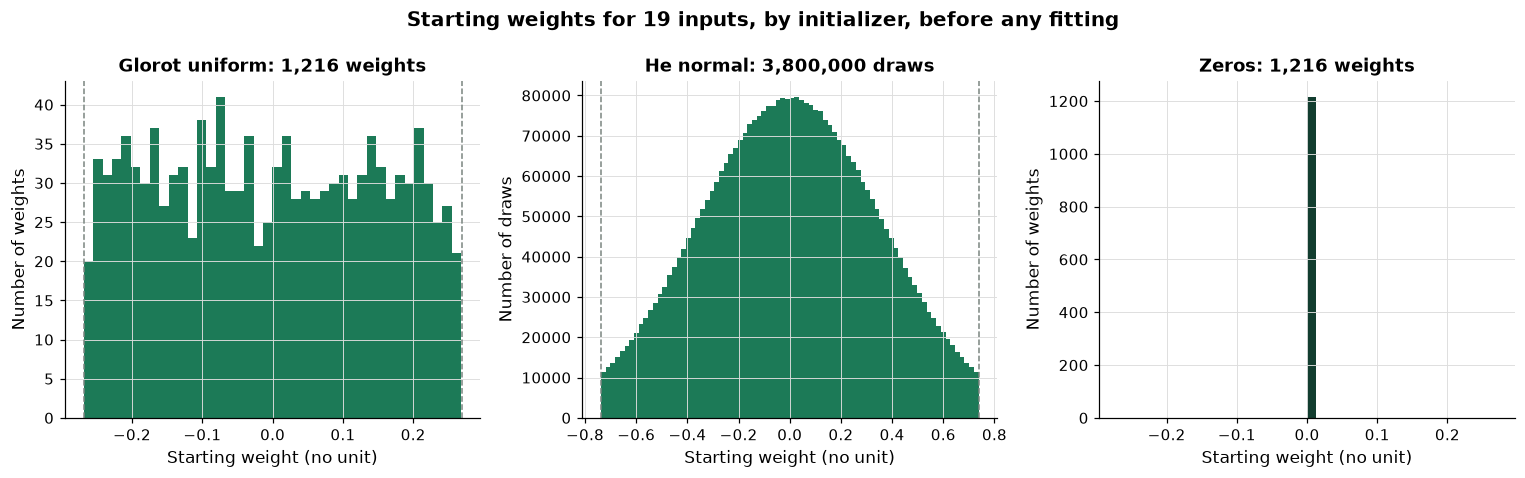

In [17]:
# a start of zeros for the third panel: every weight exactly 0
zeros_kernel = keras.initializers.Zeros()(shape=(n_inputs, 64)).numpy()
# He normal's cut: two standard deviations of the widened normal, 2 / 0.8796 of the formula's standard deviation
he_cut = 2 * he_formula / 0.87962566103423978

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
axes[0].hist(kernel.ravel(), bins=40, color=plotkit.GREEN)
axes[0].set_title(f"Glorot uniform: {kernel.size:,} weights")
axes[0].set_ylabel("Number of weights")
axes[1].hist(he_draws.ravel(), bins=80, color=plotkit.GREEN)
axes[1].set_title(f"He normal: {he_draws.size:,} draws")
axes[1].set_ylabel("Number of draws")
axes[2].hist(zeros_kernel.ravel(), bins=40, range=(-glorot_limit, glorot_limit), color=plotkit.GREEN_DARK)
axes[2].set_title(f"Zeros: {zeros_kernel.size:,} weights")
axes[2].set_ylabel("Number of weights")
# dashed lines: the Glorot limit on the first panel, He normal's cut on the second
for ax, edge in ((axes[0], glorot_limit), (axes[1], he_cut)):
    ax.axvline(-edge, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.axvline(edge, color=plotkit.GREY, linestyle="--", linewidth=1)
for ax in axes:
    ax.set_xlabel("Starting weight (no unit)")
fig.suptitle("Starting weights for 19 inputs, by initializer, before any fitting", fontweight="bold")
fig.tight_layout()
plt.show()

* Glorot uniform is flat: all 1,216 weights lie between the dashed limits, -0.2689 and 0.2689. He normal is a bell cut off at the dashed lines, 0.7377 either side of zero, with no draw beyond them. Zeros is a single bar of 1,216 weights at 0: section 8.2 shows what that start does.

Q. Glorot uniform and He normal are two of the starts Keras offers. Draw all nine it is likely to use, for a layer of 256 inputs and 256 units, and check each against the standard deviation it aims at.

In [18]:
# every initializer a Dense layer is likely to use, drawn for a layer of 256 inputs and 256 units; the formulas give
# the standard deviation each one aims for
fan_in = fan_out = 256
normal_config = keras.initializers.RandomNormal().get_config()
uniform_config = keras.initializers.RandomUniform().get_config()
aims = {
    "zeros": ("0", 0.0, "the biases (every Dense layer's default)"),
    "random_normal": (f"{normal_config['stddev']} (a fixed number)", normal_config["stddev"], "small networks; no rule for depth"),
    "random_uniform": (f"limit / sqrt(3), the limit {uniform_config['maxval']}", uniform_config["maxval"] / np.sqrt(3), "small networks; no rule for depth"),
    "glorot_uniform": ("sqrt(2 / (fan_in + fan_out))", np.sqrt(2 / (fan_in + fan_out)), "tanh, sigmoid, linear; Dense's default"),
    "glorot_normal": ("sqrt(2 / (fan_in + fan_out))", np.sqrt(2 / (fan_in + fan_out)), "tanh, sigmoid, linear"),
    "he_normal": ("sqrt(2 / fan_in)", np.sqrt(2 / fan_in), "ReLU and its relatives"),
    "he_uniform": ("sqrt(2 / fan_in)", np.sqrt(2 / fan_in), "ReLU and its relatives"),
    "lecun_normal": ("sqrt(1 / fan_in)", np.sqrt(1 / fan_in), "SELU"),
    "lecun_uniform": ("sqrt(1 / fan_in)", np.sqrt(1 / fan_in), "SELU"),
}
rows_drawn = {}
for name, (formula, aim, pair_with) in aims.items():
    # seed before drawing, so every initializer's draw never depends on what ran before
    keras.utils.set_random_seed(SEED)
    draws = keras.initializers.get(name)(shape=(fan_in, fan_out)).numpy().astype("float64")
    rows_drawn[name] = {"standard deviation aimed at": formula, "aim": aim, "measured": draws.std(), "pair it with": pair_with}
initializers = pd.DataFrame(rows_drawn).T
initializers["aim"] = initializers["aim"].astype(float)
initializers["measured"] = initializers["measured"].astype(float)
initializers.index.name = "initializer"
print(f"measured within 2 percent of the aim for every initializer but zeros: "
      f"{bool(((initializers['measured'] / initializers['aim']).drop('zeros') - 1).abs().max() < 0.02)}")
plotkit.styled(initializers, [], "Nine initializers drawn for 256 inputs and 256 units: the standard deviation each aims at, the one measured on the 65,536 draws, and what to pair it with",
               fmt="{:.4f}")

measured within 2 percent of the aim for every initializer but zeros: True


,standard deviation aimed at,aim,measured,pair it with
initializer,,,,
zeros,0,0.0000,0.0000,the biases (every Dense layer's default)
random_normal,0.05 (a fixed number),0.0500,0.0500,small networks; no rule for depth
random_uniform,"limit / sqrt(3), the limit 0.05",0.0289,0.0288,small networks; no rule for depth
glorot_uniform,sqrt(2 / (fan_in + fan_out)),0.0625,0.0624,"tanh, sigmoid, linear; Dense's default"
glorot_normal,sqrt(2 / (fan_in + fan_out)),0.0625,0.0624,"tanh, sigmoid, linear"
he_normal,sqrt(2 / fan_in),0.0884,0.0883,ReLU and its relatives
he_uniform,sqrt(2 / fan_in),0.0884,0.0883,ReLU and its relatives
lecun_normal,sqrt(1 / fan_in),0.0625,0.0624,SELU
lecun_uniform,sqrt(1 / fan_in),0.0625,0.0624,SELU


* **How to read the table.** Every initializer is a rule for the spread of the starting weights, and the rules differ in what the spread depends on. Glorot (uniform or normal) uses both the inputs and the units, 0.0625 here; He uses the inputs only and aims higher, 0.0884, because a ReLU silences about half its inputs; LeCun aims at the inputs alone, 0.0625, for SELU networks. `random_normal` and `random_uniform` ignore the layer's size altogether: their spread is a fixed number.
* The measured column agrees with the formulas to within 2 percent for every rule but zeros, so the formulas are what Keras draws. The uniform and normal forms of one rule differ only in the shape of the draw; they aim at the same spread.
* **Which to use.** Leave the default (Glorot uniform) for tanh, sigmoid, and linear layers; choose He normal for ReLU. The next sections show what the choice does to a deep network.

## 8.2 A Start of Zeros

Why random at all? Start every weight at zero and every hidden unit computes the same number from the same inputs. Each then gets the same gradient, takes the same step, and stays equal to the others, step after step. Sixteen units become sixteen copies of one.

Q. Fit the same small network twice for 5 epochs: 16 sigmoid units started at zeros, then started at Keras's default. How many different hidden units does each end with?

In [19]:
def two_layer(initializer, name):
    """16 sigmoid units and a sigmoid output, both layers starting from the given initializer."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)),
                              keras.layers.Dense(16, activation="sigmoid", kernel_initializer=initializer, name="hidden"),
                              keras.layers.Dense(1, activation="sigmoid", kernel_initializer=initializer, name="output")],
                             name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


start_compare, start_histories, start_kernels = {}, {}, {}
for initializer in ["zeros", "glorot_uniform"]:
    model = two_layer(initializer, f"start_{initializer}")
    history = model.fit(A_fit, y_fit_32, validation_data=(A_stop, y_stop_32), epochs=5, batch_size=64, verbose=0)
    hidden_kernel = model.get_layer("hidden").kernel.numpy()
    # kept for the chart below: the loss record and the hidden layer's weights after 5 epochs
    start_histories[initializer], start_kernels[initializer] = history, hidden_kernel
    # np.unique with axis=1 keeps one copy of each different column: one column per different hidden unit
    start_compare[initializer] = {"different hidden units": np.unique(hidden_kernel, axis=1).shape[1],
                                  "stopping loss after 5 epochs": history.history["val_loss"][-1]}
start_compare = pd.DataFrame.from_dict(start_compare, orient="index").astype({"different hidden units": int})
start_compare.index.name = "start"
plotkit.styled(start_compare, ["stopping loss after 5 epochs"],
               f"Two starts of the 16-unit sigmoid network after 5 epochs on the {len(A_fit):,} fit rows: different "
               f"hidden units, and mean log loss on the {len(A_stop):,} stopping rows", higher_is_better=False, fmt="{:.4f}")

,different hidden units,stopping loss after 5 epochs
start,,
zeros,1,0.4706
glorot_uniform,16,0.4646


**Rows.** Every network on the card file in this notebook is fitted on Course 4's 18,000 training rows (14,400 to fit and 3,600 to stop or choose) and scored on Course 4's 6,000 validation rows; Course 4's 6,000 test rows are never scored in this course.

* Started at zeros, the 16 columns of the hidden layer's kernel are still exactly equal after 5 epochs and 1,125 steps: one different unit, so the network is a one-unit network with 16 names. Started at random, all 16 differ. The zeros start ends at a stopping loss of 0.4706 against 0.4646.
* Random starting weights break the tie between units. The seed makes the random start the same on every run.

Q. Draw both hidden layers' weights after the 5 epochs, and both fits' loss by epoch.

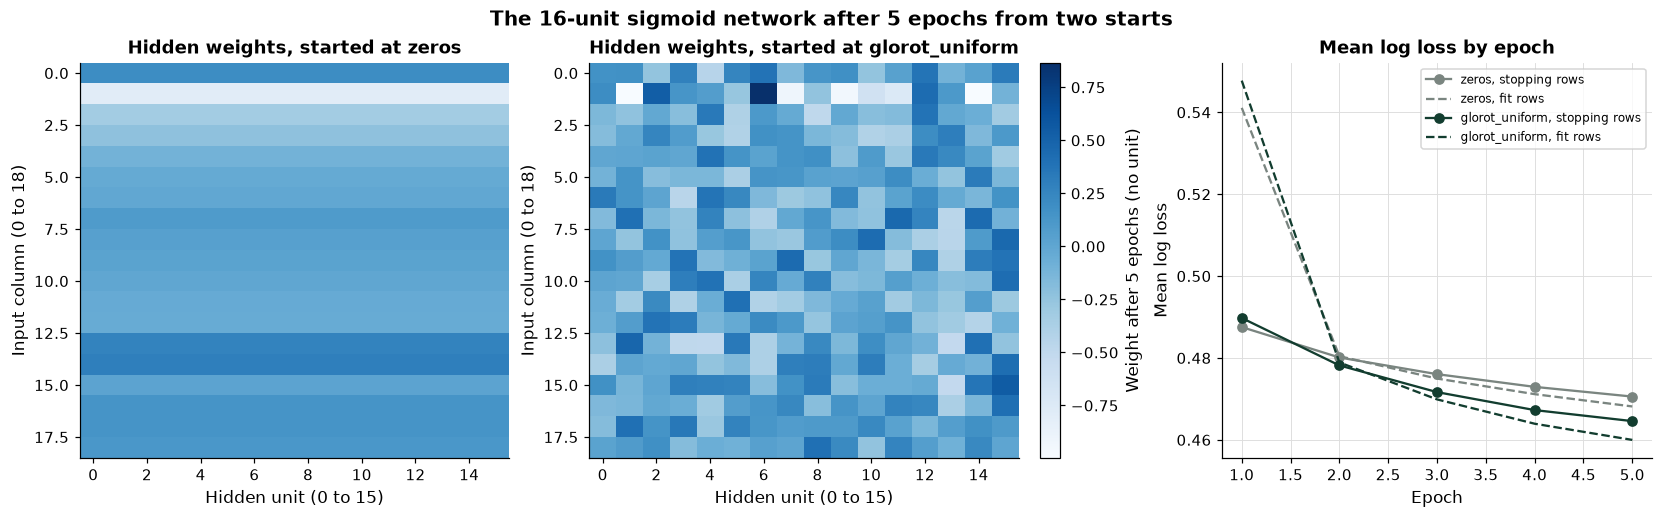

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
# one colour scale for both kernels, so equal colours mean equal weights
low = min(k.min() for k in start_kernels.values())
high = max(k.max() for k in start_kernels.values())
for ax, initializer in zip(axes[:2], ["zeros", "glorot_uniform"]):
    image = ax.imshow(start_kernels[initializer], cmap="Blues", vmin=low, vmax=high, aspect="auto")
    ax.grid(False)
    ax.set_title(f"Hidden weights, started at {initializer}")
    ax.set_xlabel("Hidden unit (0 to 15)")
    ax.set_ylabel("Input column (0 to 18)")
fig.colorbar(image, ax=axes[1], label="Weight after 5 epochs (no unit)")
# the loss on both sets of rows, epoch by epoch: solid the stopping rows, dashed the fit rows
colours = {"zeros": plotkit.GREY, "glorot_uniform": plotkit.GREEN_DARK}
for initializer, history in start_histories.items():
    table = netkit.history_table(history)
    axes[2].plot(table.index, table["val_loss"], marker="o", color=colours[initializer], label=f"{initializer}, stopping rows")
    axes[2].plot(table.index, table["loss"], linestyle="--", color=colours[initializer], label=f"{initializer}, fit rows")
axes[2].set_title("Mean log loss by epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Mean log loss")
axes[2].legend(fontsize=8)
fig.suptitle("The 16-unit sigmoid network after 5 epochs from two starts", fontweight="bold")
plt.show()

* Left: started at zeros, every input row is one colour all the way across: the 16 hidden units hold the same 19 weights. Middle: started at random, every unit has its own pattern.
* Right: after epoch 1 the zeros start's stopping loss is the lower one, by 0.0022; from epoch 2 the random start's is lower, and the gap widens every epoch, to 0.0060 after epoch 5.

## 8.3 Vanishing Gradients

**How it works.** In a deep network two things can go wrong with the numbers passed from layer to layer. The outputs, and with them the gradients that pass back through the same layers, can shrink at every layer until the first layers receive almost nothing: **vanishing gradients**. Or they can grow, or saturate an activation so that its slope is nearly zero. A start whose spread matches the layer's width and activation, and an activation whose slope is not tiny, keep both near one size from layer to layer. You control the activation and the initializer; what you read is the gradient norm by layer, and the outputs by layer.

A gradient reaches the first layer by passing back through every layer above it, multiplied at each one by the slope of that layer's activation. The sigmoid's slope is at most 0.25, so six sigmoid layers can shrink a gradient many times over before it reaches the first: the first layers' weights barely move. These are **vanishing gradients**. A ReLU's slope is 1 wherever its unit is active, so a ReLU network passes gradients back without that shrinking.

Q. Build today's deep network: six hidden layers of 32 units and a sigmoid output, in a function that seeds itself.

In [21]:
def deep_network(n_inputs, activation, initializer="glorot_uniform", batch_norm=False, name="deep"):
    """Six hidden layers of 32 units, each followed by batch normalization when batch_norm is True, and a sigmoid
    output; compiled with Adam at 1e-3 and the log loss. Every layer is named, first layer first."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,))]
    for k in range(1, 7):
        layers.append(keras.layers.Dense(32, activation=activation, kernel_initializer=initializer, name=f"hidden_{k}"))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization(name=f"norm_{k}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


deep_sigmoid = deep_network(n_inputs, "sigmoid", name="deep_sigmoid")
print(f"{deep_sigmoid.name}: {len(deep_sigmoid.layers)} Dense layers, {deep_sigmoid.count_params():,} weights and biases")

deep_sigmoid: 7 Dense layers, 5,953 weights and biases


* 5,953 weights and biases, `parameter_count([19, 32, 32, 32, 32, 32, 32, 1])` from day 3. The function takes the activation, the initializer, and whether to add batch normalization, so every network today differs from the others only where the arguments say.

To compare layers, `gradient_norms` measures each layer's gradient by one number: its Euclidean norm, the square root of the sum of its squared entries. It runs `tf.GradientTape` as day 1 did, with the model in scoring mode.

Q. Add `gradient_norms` to `netkit.py`. Read the docstring first.

In [22]:
%%writefile -a netkit.py


def gradient_norms(model, A, y) -> pd.Series:
    """The size of the loss gradient for each Dense layer's weights, on the rows given.

    Inputs: model, a compiled Keras model; A, the input rows (one batch); y, their outcomes.
    Output: a Series indexed by layer name, first layer first: the Euclidean norm of the gradient of the model's
    own loss (averaged over the rows) with respect to each Dense layer's kernel.
    Convention: computed by tf.GradientTape with the model in scoring mode (training=False), so a dropout layer
    changes nothing and a batch-normalization layer uses, and does not update, its moving averages. Very small norms
    in the first layers of a deep sigmoid network are the vanishing gradients.
    Raises ValueError if the model is not compiled or A and y differ in length.
    """
    if model.loss is None:
        raise ValueError("compile the model first: its loss is used")
    inputs = tf.constant(np.asarray(A, dtype="float32"))
    if inputs.shape[0] != len(y) or len(y) == 0:
        raise ValueError(f"A and y must be non-empty and the same length, not {inputs.shape[0]} and {len(y)}")
    dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
    loss_function = keras.losses.get(model.loss)
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)
        # the outcomes shaped like the output, so the loss compares row with row
        target = tf.reshape(tf.constant(np.asarray(y, dtype="float32")), output.shape)
        loss = tf.reduce_mean(loss_function(target, output))
    gradients = tape.gradient(loss, [layer.kernel for layer in dense])
    return pd.Series([float(tf.norm(g)) for g in gradients], index=[layer.name for layer in dense], name="gradient_norm")

Appending to netkit.py


* `keras.losses.get(model.loss)` takes the loss the model was compiled with, so the norms are of the very loss `fit` lowers.
* `training=False` scores the rows as `predict` does: a dropout layer passes everything, and a batch-normalization layer uses its moving averages and does not change them. Section 8.6 shows why that matters.

Q. Add its two tests: one norm per `Dense` layer, and agreement with a tape written out in the test.

In [23]:
%%writefile -a test_netkit.py


def test_gradient_norms_one_per_dense_layer():
    X, y = small_rows(64)
    norms = netkit.gradient_norms(small_network(dropout=0.5), X, y)
    assert norms.index.tolist() == ["hidden_1", "hidden_2", "output"]
    assert (norms > 0).all()


def test_gradient_norms_match_tape():
    X, y = small_rows(64)
    model = small_network()
    inputs = tf.constant(X.astype("float32"))
    y = y.astype("float32")
    with tf.GradientTape() as tape:
        output = model(inputs, training=False)[:, 0]
        p = tf.clip_by_value(output, 1e-7, 1 - 1e-7)
        loss = tf.reduce_mean(-(y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)))
    expected = [float(tf.norm(g)) for g in tape.gradient(loss, [layer.kernel for layer in model.layers])]
    assert netkit.gradient_norms(model, X, y).tolist() == pytest.approx(expected, rel=1e-4)

Appending to test_netkit.py


In [24]:
# the file changed, so reload before using the new function
importlib.reload(netkit)
print(f"gradient_norms in netkit: {hasattr(netkit, 'gradient_norms')}")

gradient_norms in netkit: True


In [25]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................................                                       [100%]
34 passed in 12.39s



* `34 passed`: day 7's 32 and the two new ones.

Q. At the start, how large is each layer's gradient in the deep sigmoid network, and in the same network with ReLU and He normal?

In [26]:
# the same deep shape with ReLU and the He normal start
deep_relu = deep_network(n_inputs, "relu", "he_normal", name="deep_relu_he")

# the gradient of the loss for each layer's weights, at the start, on one batch: the first 256 fit rows
norms = pd.DataFrame({"sigmoid, Glorot": netkit.gradient_norms(deep_sigmoid, A_fit[:256], y_fit_32[:256]),
                      "ReLU, He": netkit.gradient_norms(deep_relu, A_fit[:256], y_fit_32[:256])})
norms.index.name = "layer"
ratio = norms.loc["output"] / norms.loc["hidden_1"]
print(f"output layer's norm over the first layer's: sigmoid {ratio.iloc[0]:,.0f} times, ReLU {ratio.iloc[1]:,.1f} times")
plotkit.styled(norms, [], "Gradient norm of each layer's weights at the start, on the first 256 fit rows (the square "
               "root of the sum of squared entries; no unit)", fmt="{:.2e}")

output layer's norm over the first layer's: sigmoid 26,544 times, ReLU 5.3 times


,"sigmoid, Glorot","ReLU, He"
layer,,
hidden_1,4.60e-05,6.56e-01
hidden_2,9.45e-04,1.74e+00
hidden_3,4.04e-03,1.74e+00
hidden_4,1.70e-02,1.90e+00
hidden_5,9.67e-02,2.34e+00
hidden_6,3.90e-01,2.79e+00
output,1.22e+00,3.46e+00


* In the sigmoid network the norm shrinks at every layer on the way back: 1.22e+00 at the output, 4.60e-05 at the first hidden layer, 26,544 times smaller. With the same learning rate, the first layer's weights start out moving thousands of times less than the last layer's.
* With ReLU and He normal the norms stay within a factor of 5.3 from first layer to last. Every layer starts learning at once.
* A gradient is a number about the loss on these rows, not about what the network has found in the data.

Q. Draw the two columns by layer as bars.

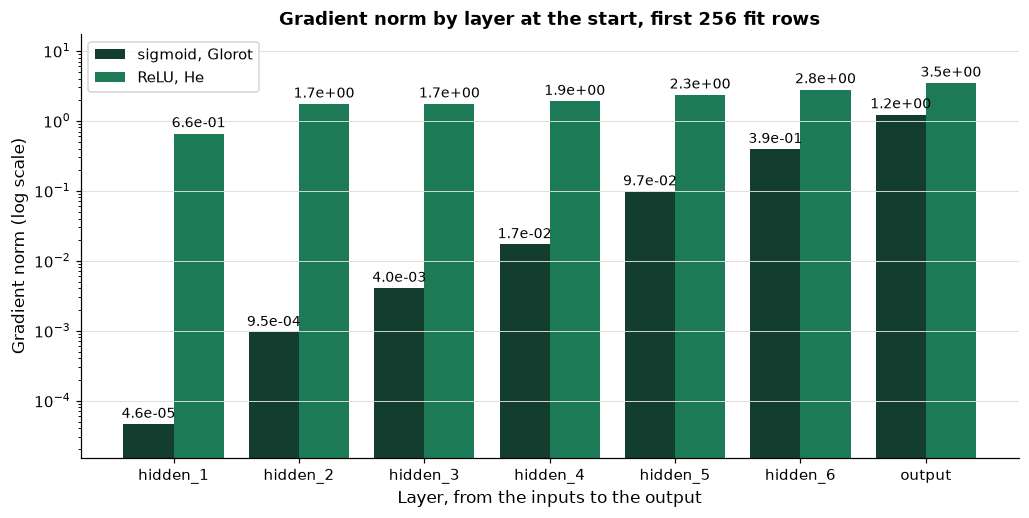

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
plotkit.bars(norms, "Gradient norm by layer at the start, first 256 fit rows", "Gradient norm (log scale)", ax=ax,
             fmt="{:.1e}")
# a log scale: each gridline is ten times the one below
ax.set_yscale("log")
ax.set_ylim(norms.min().min() / 3, norms.max().max() * 5)
ax.set_xlabel("Layer, from the inputs to the output")
plt.show()

* On a log scale each gridline is ten times the one below. The dark bars, sigmoid with Glorot, climb at every layer from the first to the output, more than 4 gridlines in all: the vanishing gradient, layer by layer. The green bars, ReLU with He, stand at about one height.

Q. The gradients shrank because the outputs did. Draw the outputs of layers 1, 3, and 6 at the start for five starts: tanh with weights of standard deviation 0.01, 1, and Glorot's, then ReLU with Glorot and with He.

In [28]:
def layer_activations(activation, initializer, rows, depth=6, width=32):
    """The output of each of `depth` Dense layers of `width` units, for the rows given, at the start (no fitting)."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(rows.shape[1],))]
    layers += [keras.layers.Dense(width, activation=activation, kernel_initializer=initializer, name=f"hidden_{k}")
               for k in range(1, depth + 1)]
    model = keras.Sequential(layers, name="probe")
    outputs, current = [], tf.constant(rows)
    for layer in model.layers:
        current = layer(current)
        outputs.append(current.numpy().astype("float64"))
    return outputs


probes = {"tanh, normal sd 0.01": ("tanh", keras.initializers.RandomNormal(stddev=0.01, seed=SEED)),
          "tanh, normal sd 1": ("tanh", keras.initializers.RandomNormal(stddev=1.0, seed=SEED)),
          "tanh, Glorot uniform": ("tanh", "glorot_uniform"),
          "ReLU, Glorot uniform": ("relu", "glorot_uniform"),
          "ReLU, He normal": ("relu", "he_normal")}
# the first 1,000 fit rows through six layers at the start: nothing is fitted
rows_probe = A_fit[:1000]
acts = {name: layer_activations(activation, initializer, rows_probe) for name, (activation, initializer) in probes.items()}

# the standard deviation of every layer's outputs, one row per start
by_layer = pd.DataFrame({name: [a.std() for a in layers] for name, layers in acts.items()},
                        index=[f"layer {k}" for k in range(1, 7)]).T
by_layer.index.name = "start"
saturated = {name: float((np.abs(layers[-1]) > 0.99).mean()) for name, layers in acts.items() if name.startswith("tanh")}
silent = {name: float((layers[-1] == 0).mean()) for name, layers in acts.items() if name.startswith("ReLU")}
print(f"tanh outputs beyond 0.99 in layer 6: normal sd 1 {saturated['tanh, normal sd 1']:.1%}, Glorot {saturated['tanh, Glorot uniform']:.1%}")
print(f"ReLU outputs exactly 0 in layer 6: Glorot {silent['ReLU, Glorot uniform']:.1%}, He {silent['ReLU, He normal']:.1%}")
plotkit.styled(by_layer, [], "Standard deviation of each layer's outputs at the start, six layers of 32 units on the first 1,000 fit rows (no unit)",
               fmt="{:.5f}")

tanh outputs beyond 0.99 in layer 6: normal sd 1 55.4%, Glorot 0.0%
ReLU outputs exactly 0 in layer 6: Glorot 51.2%, He 53.1%


,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6
start,,,,,,
"tanh, normal sd 0.01",0.04336,0.00217,0.00011,0.00001,0.00000,0.00000
"tanh, normal sd 1",0.84491,0.90167,0.91346,0.91164,0.91291,0.90641
"tanh, Glorot uniform",0.48816,0.39121,0.32042,0.28173,0.25287,0.23935
"ReLU, Glorot uniform",0.53092,0.38102,0.29253,0.18820,0.10623,0.07171
"ReLU, He normal",0.92089,0.84988,0.80684,0.88451,1.18890,1.32375


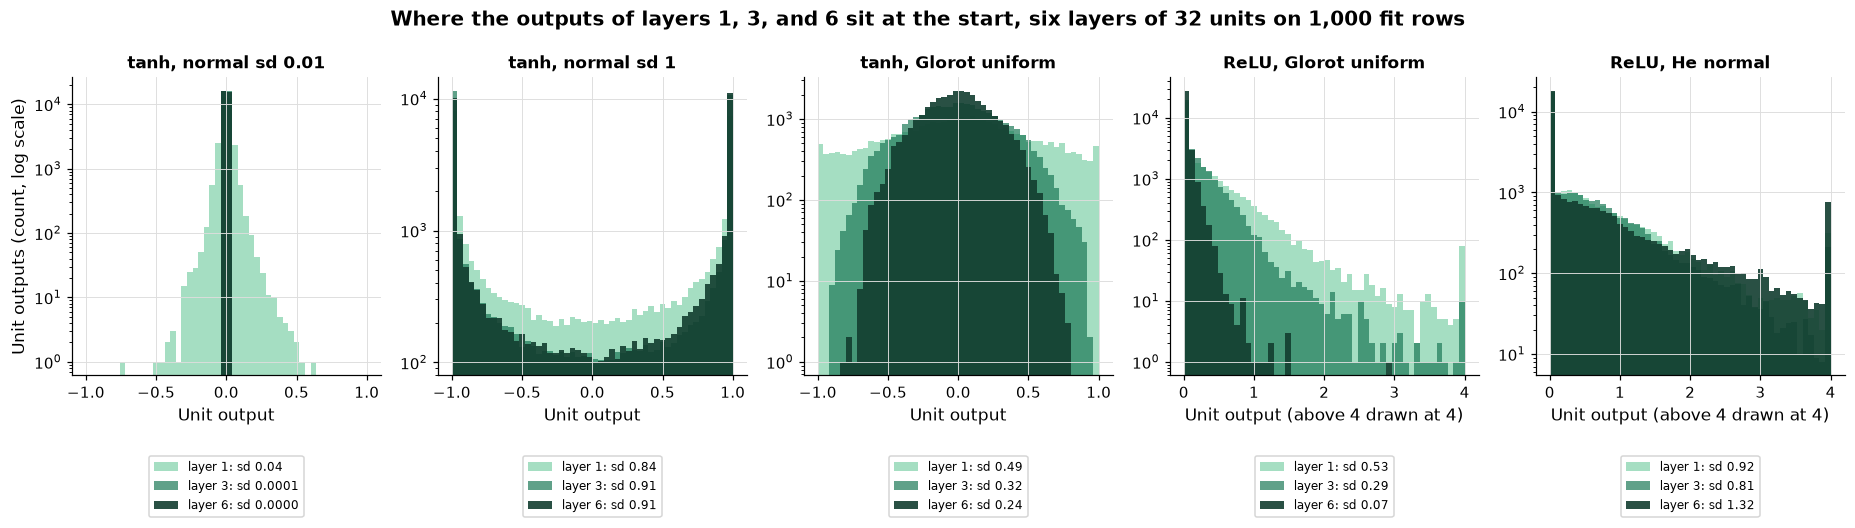

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(17, 5.2))
layer_colours = {1: plotkit.GREEN_LIGHT, 3: plotkit.GREEN, 6: plotkit.GREEN_DARK}
for axis, (name, layers) in zip(axes, acts.items()):
    # tanh outputs sit between -1 and 1, ReLU outputs from 0 up: ReLU values above 4 are drawn at 4
    is_tanh = name.startswith("tanh")
    low, high = (-1.0, 1.0) if is_tanh else (0.0, 4.0)
    for k, colour in layer_colours.items():
        values = layers[k - 1].ravel()
        axis.hist(np.clip(values, low, high), bins=50, range=(low, high), histtype="stepfilled", color=colour,
                  alpha=0.9 if k == 6 else 0.7, label=f"layer {k}: sd {values.std():.4f}" if values.std() < 0.01 else f"layer {k}: sd {values.std():.2f}")
    # a log scale: the spike at 0 and the tails both show
    axis.set_yscale("log")
    axis.set_title(name, fontsize=11)
    axis.set_xlabel("Unit output" if is_tanh else "Unit output (above 4 drawn at 4)")
    # the legend under the panel, where it covers no bar
    axis.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25))
axes[0].set_ylabel("Unit outputs (count, log scale)")
fig.suptitle("Where the outputs of layers 1, 3, and 6 sit at the start, six layers of 32 units on 1,000 fit rows", fontweight="bold")
fig.tight_layout()
plt.show()

* **How to read the grid.** Each panel overlays three layers (light green layer 1, dark green layer 6) for one start. A good start keeps the three alike; a bad one pulls the dark layer away from the light one.
* **Too small (tanh, sd 0.01).** The outputs of layer 1 already have a standard deviation of 0.04, layer 6's are 0.00000: every layer multiplies its input by numbers far below 1, so by layer 6 every unit says 0 whatever the account. The gradients pass back through the same small weights and are as small.
* **Too large (tanh, sd 1).** The outputs pile up at minus 1 and plus 1: 55.4 percent of layer 6's are beyond 0.99 in size. A tanh there has almost no slope, so gradients vanish from saturation instead.
* **Glorot, tanh.** The spread falls a little per layer, from 0.49 to 0.24, with no saturation: the rule keeps the layers in range, though the spread is not exactly held.
* **ReLU.** With Glorot the spread falls from 0.53 to 0.07, because Glorot does not allow for the half of the inputs a ReLU silences. With He it does not fall: 0.92 to 1.32. That factor of 2 in He's formula is what the picture is for.
* The table above prints the standard deviation of every layer. No network was fitted for this section: a start is judged before the first step.

## 8.4 Batch Normalization by Hand

**How it works.** Whatever the start, the layers' outputs drift while the weights change, and a deep network can drift out of range again. **Batch normalization** is a layer that puts every unit's output back on a steady scale: for each unit, subtract the mean of the batch, divide by the batch's standard deviation, then scale by a weight gamma and shift by a weight beta that the optimizer learns. The next layer then always receives numbers of about the same size, whatever the layers before it did. You control where the layer sits (after the activation here, before it in Exercise 2), and its `momentum`, `epsilon`, `center`, and `scale`. What comes out is the same shape of output, standardized, with two learned numbers and two moving averages per unit.

**Batch normalization** is a layer that standardizes each unit's output over the batch: subtract the batch's mean, divide by the batch's standard deviation, then scale by a weight gamma and shift by a weight beta that the optimizer learns (they start at 1 and 0). Keras adds a small epsilon, 0.001 (the layer's default, read from Keras 3.15.1), to the variance before the square root, and uses the **population** variance (divide by n). Every layer after it then receives numbers on a steady scale, whatever the layers before it did.

That is the layer while the network is fitted, **training mode**. Section 8.6 shows scoring time.

Q. Add `batch_norm_by_hand` to `netkit.py`, and its two tests.

In [30]:
%%writefile -a netkit.py


def batch_norm_by_hand(values, gamma: float = 1.0, beta: float = 0.0, epsilon: float = 1e-3) -> np.ndarray:
    """Batch normalization in training mode, by hand: each column standardized with the batch's own statistics.

    Inputs: values, a batch (rows by columns); gamma and beta, the layer's scale and shift (Keras starts them at 1
    and 0); epsilon, added to the variance (Keras's default 1e-3, read from the layer).
    Output: (x - column mean) / sqrt(column population variance + epsilon) * gamma + beta, in float64.
    Convention: equals keras.layers.BatchNormalization()(values, training=True) within 1e-5. At scoring time the
    layer uses moving averages instead, so one row's output does not depend on the other rows scored with it.
    Excel: =(A2-AVERAGE(A$2:A$65))/SQRT(VAR.P(A$2:A$65)+0.001).
    Raises ValueError unless values is a 2-D batch of at least one row.
    """
    batch = np.asarray(values, dtype=float)
    if batch.ndim != 2 or batch.shape[0] == 0:
        raise ValueError(f"values must be a 2-D batch of rows by columns, not shape {batch.shape}")
    # population variance (divide by n), as the layer computes it
    return (batch - batch.mean(axis=0)) / np.sqrt(batch.var(axis=0) + epsilon) * gamma + beta

Appending to netkit.py


In [31]:
%%writefile -a test_netkit.py


def test_batch_norm_by_hand_matches_layer():
    rng = np.random.default_rng(SEED)
    batch = rng.normal(loc=3.0, scale=2.0, size=(64, 4)).astype("float32")
    layer = keras.layers.BatchNormalization()
    expected = layer(batch, training=True).numpy()
    assert np.allclose(netkit.batch_norm_by_hand(batch, epsilon=layer.epsilon), expected, rtol=0, atol=1e-5)


def test_batch_norm_by_hand_column_means_zero():
    rng = np.random.default_rng(SEED)
    normalized = netkit.batch_norm_by_hand(rng.normal(loc=5.0, size=(64, 3)))
    assert np.allclose(normalized.mean(axis=0), 0.0, rtol=0, atol=1e-12)
    shifted = netkit.batch_norm_by_hand(rng.normal(size=(64, 3)), gamma=2.0, beta=1.0)
    assert np.allclose(shifted.mean(axis=0), 1.0, rtol=0, atol=1e-12)
    with pytest.raises(ValueError):
        netkit.batch_norm_by_hand(np.ones(5))

Appending to test_netkit.py


* `batch.var(axis=0)` is numpy's population variance of each column, Excel's `VAR.P`.
* The first test compares with a fresh Keras layer in training mode on a seeded batch; the second checks the column means come out at 0, or at beta when beta is 1.

Q. Reload and run all of today's tests.

In [32]:
importlib.reload(netkit)
print(f"batch_norm_by_hand in netkit: {hasattr(netkit, 'batch_norm_by_hand')}")

batch_norm_by_hand in netkit: True


In [33]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_netkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................                                     [100%]
36 passed in 12.93s



* `36 passed`: the module's two new functions, tested.

Q. Take a real batch: the first hidden layer's outputs of the deep sigmoid network for the first 64 fit rows. Normalize it by hand and with the Keras layer in training mode.

In [34]:
# demonstration: a batch-normalization layer in training mode on purpose, to check the hand version against it
# a batch of 64 rows: the first hidden layer's outputs of the deep sigmoid network for the first 64 fit rows
batch = deep_sigmoid.get_layer("hidden_1")(A_fit[:64]).numpy()
by_hand = netkit.batch_norm_by_hand(batch)
layer_out = keras.layers.BatchNormalization()(batch, training=True).numpy()

print(f"batch shape {batch.shape}")
print(f"before: column means from {batch.mean(axis=0).min():.4f} to {batch.mean(axis=0).max():.4f}, "
      f"standard deviations from {batch.std(axis=0).min():.4f} to {batch.std(axis=0).max():.4f}")
print(f"after: largest absolute column mean {np.abs(by_hand.mean(axis=0)).max():.4f}, "
      f"standard deviations from {by_hand.std(axis=0).min():.4f} to {by_hand.std(axis=0).max():.4f}")
print(f"by hand equal to the layer in training mode within 1e-5: {np.abs(by_hand - layer_out).max() < 1e-5}")

batch shape (64, 32)
before: column means from 0.4725 to 0.5473, standard deviations from 0.0912 to 0.2196
after: largest absolute column mean 0.0000, standard deviations from 0.9449 to 0.9898
by hand equal to the layer in training mode within 1e-5: True


* Before: sigmoid outputs, every column near 0.5 with a small spread. After: every column has mean 0 and a standard deviation just under 1 (just under because of the epsilon on small variances). The hand version equals the layer within 1e-5, the float32 tolerance.
* This cell asks for training mode with `training=True` on purpose, as a demonstration. Nowhere else in the course is a network scored that way; section 8.6 says why.

Q. Draw the batch's values before and after normalization.

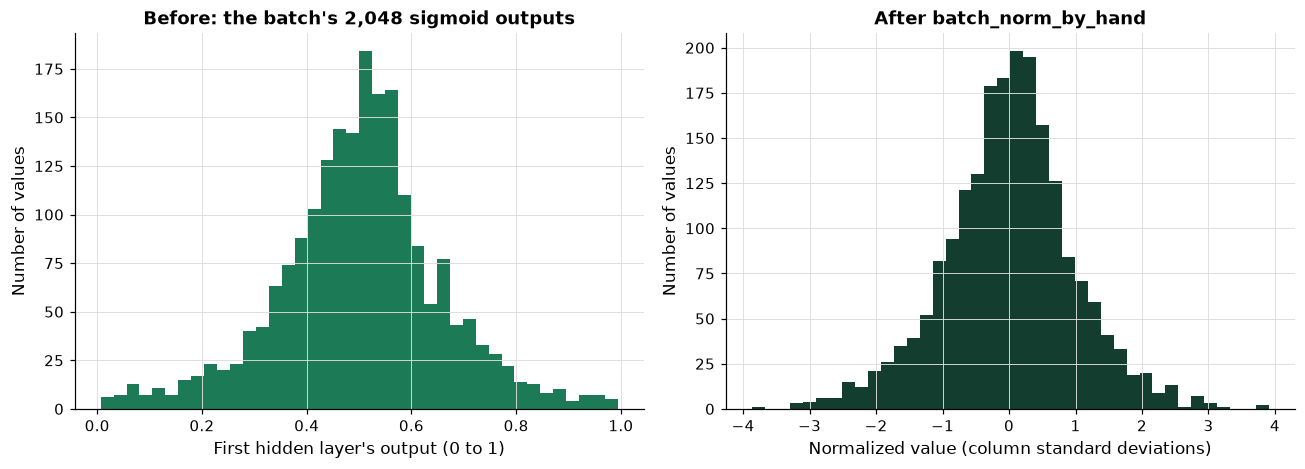

In [35]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4))
left.hist(batch.ravel(), bins=40, color=plotkit.GREEN)
left.set_title(f"Before: the batch's {batch.size:,} sigmoid outputs")
left.set_xlabel("First hidden layer's output (0 to 1)")
right.hist(by_hand.ravel(), bins=40, color=plotkit.GREEN_DARK)
right.set_title("After batch_norm_by_hand")
right.set_xlabel("Normalized value (column standard deviations)")
for ax in (left, right):
    ax.set_ylabel("Number of values")
fig.tight_layout()
plt.show()

* Before, every value is a sigmoid output between 0 and 1 (0.0067 to 0.9943). After, the same 2,048 values run from -3.87 to 3.91, centred on 0: each column now has mean 0 and a standard deviation just under 1, whatever its spread before. That is the scale every layer after it receives.

## 8.5 Four Deep Networks, One Setting at a Time

Now fit the deep network, and change one setting at a time:

* **Model 1**: six sigmoid layers, Glorot uniform start.
* **Model 2**: Model 1 with batch normalization after each hidden layer.
* **Model 3**: Model 1 with ReLU and the He normal start (the activation and the start that goes with it, counted as one setting).
* **Model 4**: Model 3 with batch normalization after each hidden layer.

Each is fitted with Adam at 1e-3, batch 64, for up to 40 epochs, with early stopping on the stopping rows (patience 10, best weights restored), and compared on the stopping rows' log loss.

Q. Fit the four.

In [36]:
# four deep networks, one setting changed at a time; each fitted on the fit rows and stopped on the stopping rows
ladder = {"model_1_sigmoid": ("sigmoid", "glorot_uniform", False),
          "model_2_sigmoid_batch_norm": ("sigmoid", "glorot_uniform", True),
          "model_3_relu_he": ("relu", "he_normal", False),
          "model_4_relu_he_batch_norm": ("relu", "he_normal", True)}
histories, networks = {}, {}
for name, (activation, initializer, batch_norm) in ladder.items():
    network = deep_network(n_inputs, activation, initializer, batch_norm, name=name)
    stop_early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = network.fit(A_fit, y_fit_32, validation_data=(A_stop, y_stop_32), epochs=40, batch_size=64,
                          verbose=0, callbacks=[stop_early])
    histories[name], networks[name] = history, network

summary = pd.DataFrame.from_dict(
    {name: {"epochs run": len(h.history["loss"]), "best epoch": netkit.best_epoch(h),
            "best stopping loss": min(h.history["val_loss"]), "first epoch stopping loss": h.history["val_loss"][0]}
     for name, h in histories.items()}, orient="index").astype({"epochs run": int, "best epoch": int})
summary.index.name = "model"
chosen = summary["best stopping loss"].idxmin()
print(f"lowest stopping loss: {chosen}")
plotkit.styled(summary, ["best stopping loss"],
               f"Four deep networks fitted on the {len(A_fit):,} fit rows, early stopping on the {len(A_stop):,} "
               "stopping rows: mean log loss there (lowest best stopping loss marked)", higher_is_better=False,
               fmt="{:.4f}")

lowest stopping loss: model_2_sigmoid_batch_norm


,epochs run,best epoch,best stopping loss,first epoch stopping loss
model,,,,
model_1_sigmoid,40,40,0.4528,0.5274
model_2_sigmoid_batch_norm,21,11,0.4379,0.5299
model_3_relu_he,17,7,0.4466,0.4726
model_4_relu_he_batch_norm,12,2,0.4505,0.4635


* **Model 1** never stopped: its best epoch is the 40th, the cap, and its stopping loss was still falling slowly (0.4528). Its first layers learn slowly, as section 8.3's gradients said they would.
* **Model 2**, one setting changed from Model 1: batch normalization after each hidden layer; chosen on the 3,600 stopping rows. The lowest stopping loss, 0.4379 at epoch 11, and early stopping ended it at epoch 21.
* **Model 3**, one setting changed from Model 1: the activation and its start, sigmoid with Glorot to ReLU with He; chosen on the 3,600 stopping rows. A much better first epoch (0.4726 against 0.5274) and a best of 0.4466.
* **Model 4**, one setting changed from Model 3: batch normalization; chosen on the 3,600 stopping rows. Its best, 0.4505 at epoch 2, is above Model 3's: on this file batch normalization helped the sigmoid network and not the ReLU one.
* The gaps are a few thousandths of log loss. Day 4's seed spread is the yardstick for how much of a gap that size the seed alone can make; the order of Models 2, 3, and 4 is the order this seed gave.

Q. Draw each pair's loss by epoch, without and with batch normalization: the sigmoid networks on the left, the ReLU networks on the right.

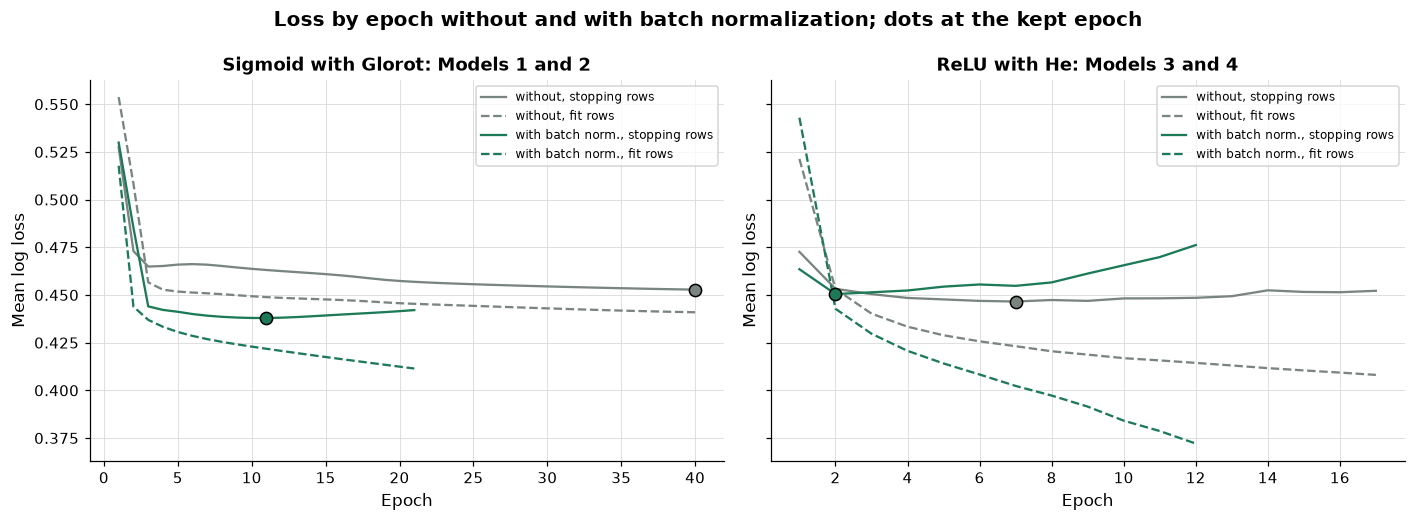

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
pairs = [("Sigmoid with Glorot: Models 1 and 2", "model_1_sigmoid", "model_2_sigmoid_batch_norm"),
         ("ReLU with He: Models 3 and 4", "model_3_relu_he", "model_4_relu_he_batch_norm")]
for ax, (title, without, with_norm) in zip(axes, pairs):
    for name, colour, label in [(without, plotkit.GREY, "without"), (with_norm, plotkit.GREEN, "with batch norm.")]:
        table = netkit.history_table(histories[name])
        ax.plot(table.index, table["val_loss"], color=colour, label=f"{label}, stopping rows")
        ax.plot(table.index, table["loss"], color=colour, linestyle="--", label=f"{label}, fit rows")
        # a dot at the epoch whose weights early stopping kept
        kept = netkit.best_epoch(histories[name])
        ax.plot(kept, table.loc[kept, "val_loss"], "o", color=colour, markersize=8, markeredgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean log loss")
    ax.legend(fontsize=8)
fig.suptitle("Loss by epoch without and with batch normalization; dots at the kept epoch", fontweight="bold")
fig.tight_layout()
plt.show()

* Left: with batch normalization (green) the sigmoid network's stopping loss starts higher (0.5299 against 0.5274), is below Model 1's from epoch 3 on, and reaches its kept epoch, 11, while Model 1 is still falling at the cap. On the fit rows (dashed) Model 2 is lower at every epoch.
* Right: batch normalization lowers the ReLU network's first stopping loss (0.4635 against 0.4726), but after epoch 2 its stopping loss climbs while its fit loss keeps falling, to 0.3721, the lowest of the four: it fits its own rows more closely and the stopping rows less well. Day 9 is about that gap.

## 8.6 At Scoring Time: the Moving Averages

**How it works.** A batch-normalization layer behaves differently while a network is fitted and when it is used. While it fits, it standardizes with the batch's own mean and variance, and at every step it moves a **moving average** of those two numbers a little toward the batch's. At scoring time it stops using batches and uses the moving averages instead, so an account's output depends only on its own row and the fitted network. You control how fast the averages follow the batches (`momentum`) and which mode runs: `predict` scores in the scoring mode, and `training=True` forces the fitting mode. What comes out is an output for each account that does not depend on which other accounts are scored with it.

In training mode a batch-normalization layer uses the batch's own mean and variance. That cannot work at scoring time: an account's output would depend on which other accounts happened to be in the batch, and an account scored alone would have no spread to divide by. So while it fits, the layer also keeps a **moving average** of the batch means and variances (each batch moves them 1 percent of the way, Keras's `momentum=0.99`), and at scoring time it uses those instead. `predict` scores in that mode.

Q. What does each batch-normalization layer keep, and which of its numbers does the optimizer learn?

In [38]:
network = networks["model_2_sigmoid_batch_norm"]
norm_1 = network.get_layer("norm_1")
# each batch-normalization layer keeps four numbers per unit: two it learns, two it averages while fitting
for weight in norm_1.weights:
    how = "learned by the optimizer" if weight.trainable else "a moving average, updated while fitting"
    print(f"{weight.name}: {weight.shape[0]} numbers, {how}")
trainable = sum(int(np.prod(w.shape)) for w in network.trainable_weights)
print(f"{network.name}: {network.count_params():,} numbers, of which {trainable:,} learned and "
      f"{network.count_params() - trainable:,} moving averages")

gamma: 32 numbers, learned by the optimizer
beta: 32 numbers, learned by the optimizer
moving_mean: 32 numbers, a moving average, updated while fitting
moving_variance: 32 numbers, a moving average, updated while fitting
model_2_sigmoid_batch_norm: 6,721 numbers, of which 6,337 learned and 384 moving averages


* Four numbers per unit: gamma and beta, learned by the optimizer like any weight, and the moving mean and moving variance, which are updated by averaging, not by gradients. Six layers of 32 units add 384 moving averages, which is why `count_params()` (6,721) is larger than the number of learned weights (6,337).

Q. Score account 0 of the validation rows on its own, then among all 6,000. Same output?

In [39]:
# account 0 of the validation rows scored on its own, and among all 6,000
alone = network.predict(A_valid[:1], verbose=0)[0, 0]
among = network.predict(A_valid, verbose=0)[:, 0]
print(f"account 0 alone {alone:.4f}, among the 6,000 {among[0]:.4f}")
print(f"the same within 1e-6: {abs(alone - among[0]) < 1e-6}")

account 0 alone 0.2689, among the 6,000 0.2689
the same within 1e-6: True


* 0.2689 both ways. In scoring mode each account's output depends only on its own row and the fitted network.

Q. What would training mode do at scoring time? Score three accounts one at a time with `training=True`, then put the weights back.

In [40]:
# demonstration: the layer in training mode at scoring time, on purpose, to see what it does; then undo it
saved = network.get_weights()
moving_mean_before = norm_1.moving_mean.numpy().copy()
one_at_a_time = [float(network(A_valid[k:k + 1], training=True)[0, 0]) for k in range(3)]
print(f"training mode, accounts 0, 1, 2 each scored alone: {[round(v, 4) for v in one_at_a_time]}")
print(f"scoring mode, the same accounts: {[round(float(v), 4) for v in among[:3]]}")
moved = not np.array_equal(moving_mean_before, norm_1.moving_mean.numpy())
print(f"the training-mode runs moved norm_1's moving mean: {moved}")
# put every weight back as it was, moving averages included
network.set_weights(saved)
print(f"after set_weights, scoring mode is back: {bool(np.array_equal(network.predict(A_valid, verbose=0)[:, 0], among))}")

training mode, accounts 0, 1, 2 each scored alone: [0.167, 0.167, 0.167]
scoring mode, the same accounts: [0.2689, 0.0481, 0.1756]
the training-mode runs moved norm_1's moving mean: True
after set_weights, scoring mode is back: True


* All three get the same output, 0.1670. A batch of one row has a mean equal to the row and no spread, so every unit normalizes to zero and only beta is left: the network gives one number for every account. In scoring mode the same three accounts get 0.2689, 0.0481, 0.1756.
* Worse, each training-mode run moved the moving averages, so the fitted network itself changed. `get_weights` saved every number first and `set_weights` put them back; without that, every later score would come from a different network. Exercise 5 is this bug as an AI assistant might write it.

Q. Draw the three accounts' outputs in the two modes.

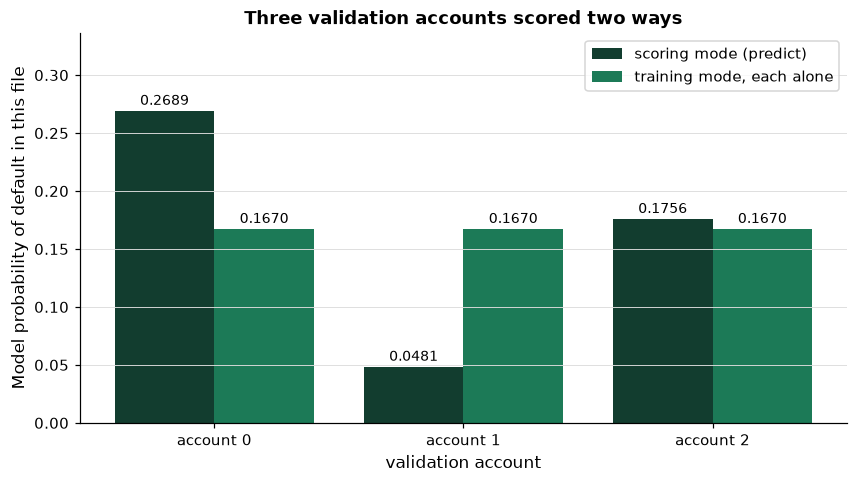

,scoring mode (predict),"training mode, each alone"
validation account,,
account 0,0.2689,0.1670
account 1,0.0481,0.1670
account 2,0.1756,0.1670


In [41]:
modes = pd.DataFrame({"scoring mode (predict)": among[:3], "training mode, each alone": one_at_a_time},
                     index=pd.Index(["account 0", "account 1", "account 2"], name="validation account"))
fig, ax = plt.subplots(figsize=(9, 4.6))
plotkit.bars(modes, "Three validation accounts scored two ways", "Model probability of default in this file", ax=ax,
             fmt="{:.4f}")
# room above the tallest bar for its label
ax.set_ylim(0, 1.25 * modes.to_numpy().max())
plt.show()
plotkit.styled(modes, [], "Three validation accounts: the output in scoring mode (predict), and in training mode with "
               "each account scored alone", fmt="{:.4f}")

* The green bars, training mode, are one height: 0.1670 for every account. The dark bars, scoring mode, differ account by account. Only scoring mode tells the accounts apart.

### Every setting of `keras.layers.BatchNormalization`

The layer has 17 settings. The table lists all of them with the default the installed Keras uses, read from its signature rather than typed, what each controls, and what raising and lowering it does. Leave nearly all of them at their defaults: the layer was designed so that the defaults work. The one with a number worth knowing is `momentum`, the moving average's memory from this section; the rest are choices of what the layer learns and where it starts.

Q. Build the table from Keras itself.

In [42]:
import inspect

# the defaults come from the installed Keras's own signature, so they are never typed
signature = inspect.signature(keras.layers.BatchNormalization.__init__)
defaults = {name: p.default for name, p in signature.parameters.items() if name not in ("self", "kwargs")}

# setting: (group, what it controls, raising it, lowering it, tune first)
notes = {
    'axis': ('what is normalized', 'the axis whose units are standardized, normally the features axis; -1 is the last, the units of a Dense layer', 'a choice, not a dial: use the features axis (1 for channels-first images)', 'a choice, not a dial', ''),
    'momentum': ('moving averages', 'how slowly the moving mean and variance used at scoring time follow the batches: about 1 / (1 - momentum) steps of memory', 'a steadier average that lags: at 0.99 the starting values are still 10 percent of it after one epoch of 225 steps', 'an average that follows recent batches and is noisier', 'short fits only'),
    'epsilon': ('stability', 'added to the batch variance before the square root, so a unit with no spread never divides by zero', 'units with a tiny variance are damped more', 'closer to the exact standardization', ''),
    'center': ('learned shift', 'whether the layer learns an offset beta for each unit after standardizing', "True: each unit's mean can move away from 0", 'False: every unit stays centred on 0', ''),
    'scale': ('learned scale', 'whether the layer learns a multiplier gamma for each unit after standardizing', "True: each unit's spread can widen or narrow", 'False: every unit keeps spread 1; Keras says it can be off when the next layer is linear', ''),
    'beta_initializer': ('starting values', 'where beta starts; zeros, so the layer starts as pure standardizing', 'a choice', 'a choice', ''),
    'gamma_initializer': ('starting values', 'where gamma starts; ones, so the layer starts as pure standardizing', 'a choice', 'a choice', ''),
    'moving_mean_initializer': ('starting values', 'where the moving mean starts, before any batch has moved it', 'a choice', 'a choice', ''),
    'moving_variance_initializer': ('starting values', 'where the moving variance starts, before any batch has moved it', 'a choice', 'a choice', ''),
    'beta_regularizer': ('penalties', 'an optional penalty on beta; None means none', 'a stronger pull of beta toward 0', 'None leaves beta alone', ''),
    'gamma_regularizer': ('penalties', 'an optional penalty on gamma; None means none', 'a stronger pull of gamma toward 0', 'None leaves gamma alone', ''),
    'beta_constraint': ('penalties', "an optional limit on beta's values; None means none", 'a looser limit', 'a tighter limit', ''),
    'gamma_constraint': ('penalties', "an optional limit on gamma's values; None means none", 'a looser limit', 'a tighter limit', ''),
    'renorm': ('renormalization', 'whether to use Batch Renormalization, which adds extra variables during training; scoring is the same either way', 'True: for batches too small or too unlike each other for their own statistics', 'False: plain batch normalization', ''),
    'renorm_clipping': ('renormalization', 'clips the renormalization correction; used only if renorm is True', 'a looser clip', 'a tighter clip', ''),
    'renorm_momentum': ('renormalization', "how the renormalization's own moving statistics follow the batches; used only if renorm is True", 'stale estimates if too large', 'noise if too small', ''),
    'synchronized': ('housekeeping', 'on the TensorFlow backend with several devices, whether batch statistics are shared across them; irrelevant on one CPU', 'True: shared statistics across devices', 'False: each device uses its own', ''),
}
# every setting Keras has is described, and nothing else
assert set(notes) == set(defaults)

settings = pd.DataFrame({name: [notes[name][0], repr(defaults[name]), *notes[name][1:]] for name in defaults},
                        index=["group", "default", "what it controls", "raising it", "lowering it", "tune first"]).T
settings.index.name = "setting"
print(f"keras.layers.BatchNormalization has {len(defaults)} settings; the defaults are read from the installed Keras")
# the moving average's memory: steps, and the share of the starting value left after one epoch of 225 steps
memory = 1 / (1 - defaults["momentum"])
print(f"momentum {defaults['momentum']}: a memory of about {memory:.0f} steps; after 225 steps {defaults['momentum'] ** 225:.1%} of the average is still its starting value")
# a table of words: nothing is marked
plotkit.styled(settings, [], "Every setting of keras.layers.BatchNormalization: its default, what it controls, and what raising or lowering it does")

keras.layers.BatchNormalization has 17 settings; the defaults are read from the installed Keras
momentum 0.99: a memory of about 100 steps; after 225 steps 10.4% of the average is still its starting value


,group,default,what it controls,raising it,lowering it,tune first
setting,,,,,,
axis,what is normalized,-1,"the axis whose units are standardized, normally the features axis; -1 is the last, the units of a Dense layer","a choice, not a dial: use the features axis (1 for channels-first images)","a choice, not a dial",
momentum,moving averages,0.99,how slowly the moving mean and variance used at scoring time follow the batches: about 1 / (1 - momentum) steps of memory,a steadier average that lags: at 0.99 the starting values are still 10 percent of it after one epoch of 225 steps,an average that follows recent batches and is noisier,short fits only
epsilon,stability,0.001,"added to the batch variance before the square root, so a unit with no spread never divides by zero",units with a tiny variance are damped more,closer to the exact standardization,
center,learned shift,True,whether the layer learns an offset beta for each unit after standardizing,True: each unit's mean can move away from 0,False: every unit stays centred on 0,
scale,learned scale,True,whether the layer learns a multiplier gamma for each unit after standardizing,True: each unit's spread can widen or narrow,False: every unit keeps spread 1; Keras says it can be off when the next layer is linear,
beta_initializer,starting values,'zeros',"where beta starts; zeros, so the layer starts as pure standardizing",a choice,a choice,
gamma_initializer,starting values,'ones',"where gamma starts; ones, so the layer starts as pure standardizing",a choice,a choice,
moving_mean_initializer,starting values,'zeros',"where the moving mean starts, before any batch has moved it",a choice,a choice,
moving_variance_initializer,starting values,'ones',"where the moving variance starts, before any batch has moved it",a choice,a choice,


* 17 settings, and every default is Keras's own: `momentum` 0.99, `epsilon` 0.001, a learned shift and scale on (`center` and `scale` True), and every optional penalty and constraint off (`None`).
* **Tune first:** none; if one, `momentum`. Its memory is about 100 steps, so after one epoch of 225 steps a tenth of the moving average is still its starting value. Fit for only a few hundred steps and the scoring-time statistics lag the fitted network; lower `momentum` (0.9 has a memory of 10 steps) then follows the batches more closely, at the cost of noise.
* Exercise 5 is the bug that skips the moving averages altogether, by scoring in training mode.

## 8.7 The Chosen Network on the Validation Rows

Model 2 had the lowest stopping loss. It is scored once on the validation rows, and its threshold for recall 0.70 comes from its outputs on the stopping rows, which are training rows. (Day 5 took the threshold from out-of-fold outputs, five fits of the network; today the stopping rows stand in, to keep the notebook inside its time budget.)

Q. Score the chosen network on the validation rows.

In [43]:
# the chosen network, scored once on the validation rows
network = networks[chosen]
output_valid = network.predict(A_valid, verbose=0)[:, 0]
print(f"{chosen}: validation ROC AUC {roc_auc_score(y_valid, output_valid):.4f}, "
      f"average precision {average_precision_score(y_valid, output_valid):.4f}")

# the threshold for recall 0.70 from its outputs on the stopping rows: training rows, never the validation rows
output_stop = network.predict(A_stop, verbose=0)[:, 0]
threshold = mlkit.threshold_for_recall(y_stop, output_stop, 0.70)
flags = (output_valid >= threshold).astype(int)
metrics = mlkit.classification_metrics(y_valid, flags)
print(f"threshold for recall 0.70 on the stopping rows: {threshold:.4f}")
print(f"at that threshold on the validation rows: recall {metrics['recall']:.4f}, precision {metrics['precision']:.4f}, "
      f"accounts flagged {flags.sum():,} of {len(flags):,}")

model_2_sigmoid_batch_norm: validation ROC AUC 0.7704, average precision 0.5283
threshold for recall 0.70 on the stopping rows: 0.1949
at that threshold on the validation rows: recall 0.6797, precision 0.4020, accounts flagged 2,244 of 6,000


* Validation ROC AUC 0.7704 and average precision 0.5283: the model probability of default in this file, scored once, labelled validation.
* At the threshold of 0.1949 chosen on the stopping rows, recall on the validation rows is 0.6797, a little short of the 0.70 it was chosen for: a threshold carries over to new rows only approximately. Precision is 0.4020, with 2,244 of 6,000 accounts flagged.

Q. Draw the chosen network's ROC and precision-recall curves on the stopping rows, where the threshold was chosen, and on the validation rows, with the threshold marked on each.

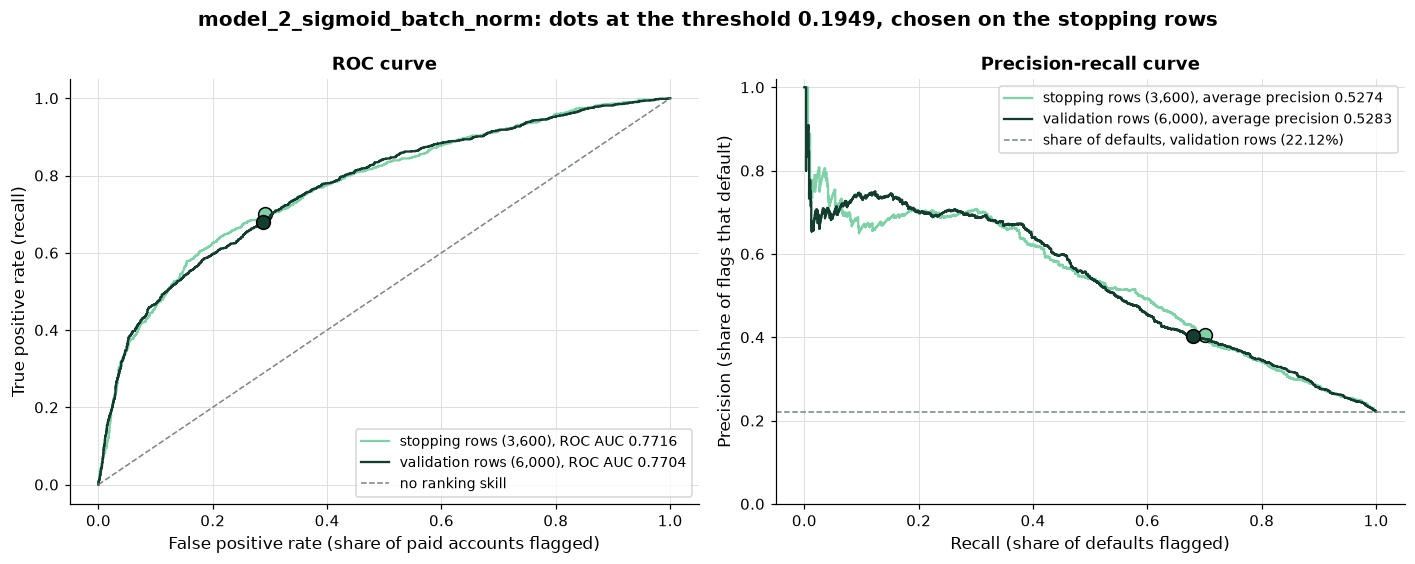

In [44]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.2))
for rows_name, outcome, output, colour in [(f"stopping rows ({len(y_stop):,})", y_stop, output_stop, plotkit.GREEN_LIGHT),
                                           (f"validation rows ({len(y_valid):,})", y_valid, output_valid, plotkit.GREEN_DARK)]:
    actual = np.asarray(outcome) == 1
    flagged = output >= threshold
    false_rate, true_rate, _ = roc_curve(outcome, output)
    precision_line, recall_line, _ = precision_recall_curve(outcome, output)
    left.plot(false_rate, true_rate, color=colour, label=f"{rows_name}, ROC AUC {roc_auc_score(outcome, output):.4f}")
    right.step(recall_line, precision_line, where="post", color=colour,
               label=f"{rows_name}, average precision {average_precision_score(outcome, output):.4f}")
    # the threshold as a point on each curve: the share of each class flagged, and the share of flags that default
    left.plot(flagged[~actual].mean(), flagged[actual].mean(), "o", color=colour, markersize=9, markeredgecolor="black")
    right.plot(flagged[actual].mean(), actual[flagged].mean(), "o", color=colour, markersize=9, markeredgecolor="black")
left.plot([0, 1], [0, 1], color=plotkit.GREY, linestyle="--", linewidth=1, label="no ranking skill")
left.set_xlabel("False positive rate (share of paid accounts flagged)")
left.set_ylabel("True positive rate (recall)")
left.set_title("ROC curve")
left.legend(loc="lower right", fontsize=9)
right.axhline(y_valid.mean(), color=plotkit.GREY, linestyle="--", linewidth=1,
              label=f"share of defaults, validation rows ({y_valid.mean():.2%})")
right.set_xlabel("Recall (share of defaults flagged)")
right.set_ylabel("Precision (share of flags that default)")
right.set_ylim(0, 1.02)
right.set_title("Precision-recall curve")
right.legend(loc="upper right", fontsize=9)
fig.suptitle(f"{chosen}: dots at the threshold {threshold:.4f}, chosen on the stopping rows", fontweight="bold")
fig.tight_layout()
plt.show()

* The two pairs of curves nearly coincide: ROC AUC 0.7716 on the stopping rows against 0.7704 on validation, average precision 0.5274 against 0.5283. The dots sit at recall 0.7010 on the stopping rows, where the threshold was set to reach 0.70, and 0.6797 on validation.

Q. Draw its confusion matrices at that threshold on the fit, stopping, and validation rows.

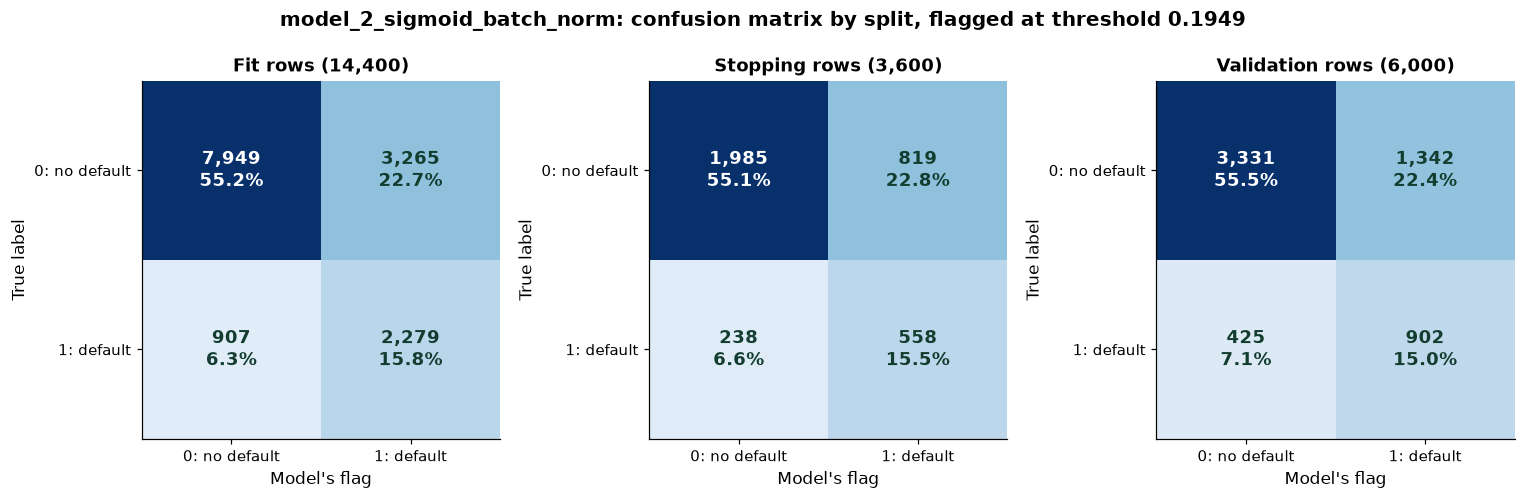

,accuracy,precision,recall,f1,accounts flagged
rows,,,,,
"fit rows (14,400)",0.7103,0.4111,0.7153,0.5221,"5,544"
"stopping rows (3,600)",0.7064,0.4052,0.7010,0.5136,"1,377"
"validation rows (6,000)",0.7055,0.4020,0.6797,0.5052,"2,244"


In [45]:
# the names of class 0 and class 1, used on every heatmap in the course
labels = ("0: no default", "1: default")
output_fit = network.predict(A_fit, verbose=0)[:, 0]
splits = {f"fit rows ({len(y_fit):,})": (y_fit, output_fit), f"stopping rows ({len(y_stop):,})": (y_stop, output_stop),
          f"validation rows ({len(y_valid):,})": (y_valid, output_valid)}
flag_rows = {}
# a Keras model has no predict_proba, so each panel is drawn from its outputs flagged at the threshold
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (rows_name, (outcome, output)) in zip(axes, splits.items()):
    flag = (output >= threshold).astype(int)
    plotkit.confusion_heatmap(outcome, flag, rows_name.capitalize(), labels, ax=ax)
    flag_rows[rows_name] = mlkit.classification_metrics(outcome, flag) | {"accounts flagged": int(flag.sum())}
fig.suptitle(f"{chosen}: confusion matrix by split, flagged at threshold {threshold:.4f}", fontweight="bold")
fig.tight_layout()
plt.show()
flag_table = pd.DataFrame.from_dict(flag_rows, orient="index").astype({"accounts flagged": int})
flag_table.index.name = "rows"
plotkit.styled(flag_table, [], f"{chosen} flagged at threshold {threshold:.4f}, chosen on the stopping rows, by split",
               fmt="{:.4f}")

* Recall falls a little from the rows the network was fitted on to the rows it never saw: 0.7153 on the fit rows, 0.7010 on the stopping rows, 0.6797 on validation. Precision follows: 0.4111, 0.4052, 0.4020. The threshold flags 38.5%, 38.2%, and 37.4% of the accounts.

> **STORY: the name of the layer.** On 11 February 2015 Sergey Ioffe and Christian Szegedy posted a paper titled "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift" on arXiv (number 1502.03167). Its title names the layer this notebook takes apart: each unit standardized with its batch's own mean and variance while the network is fitted.
>
> Source (read 2026-10-06): the arXiv record of the paper, https://arxiv.org/abs/1502.03167 (metadata read through export.arxiv.org). Only the title, authors, arXiv number, and date of the first version are taken from it; the paper itself was not read for this course.

## Excel Side by Side

Excel has no network layers and no training: nothing in it draws starting weights, runs a gradient tape, or keeps a moving average while fitting. What Excel can do is the arithmetic of today's two formulas. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-06, and the foundation's check on the same version for the first two rows). For batch normalization, the batch of section 8.4 (64 rows by 32 hidden outputs) was pasted into A2:AF65 of a sheet named `batch`.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Glorot uniform limit, 19 inputs, 64 units | `np.sqrt(6 / (19 + 64))` | `=SQRT(6/(19+64))` | 0.268866 |
| He normal standard deviation, 19 inputs | `np.sqrt(2 / 19)` | `=SQRT(2/19)` | 0.324443 |
| Batch normalization in training mode | `netkit.batch_norm_by_hand(batch)` | `=(A2-AVERAGE(A$2:A$65))/SQRT(VAR.P(A$2:A$65)+0.001)` in AH2, filled across to BM and down to row 65 | equal to `batch_norm_by_hand` within 1e-12, to the Keras layer within 1e-5 |
| Each normalized column's mean | `by_hand.mean(axis=0)` | `=AVERAGE(AH2:AH65)`, filled across | 0 within 1e-12 |
| Each normalized column's variance | `by_hand.var(axis=0)` | `=VAR.P(AH2:AH65)`, filled across | v / (v + 0.001), v the column's variance, within 1e-12 |

**The two starting rules are one formula each.** `=SQRT(6/(19+64))` is the limit every Glorot weight of a 19-input, 64-unit layer stays inside; `=SQRT(2/19)` is the He normal standard deviation. Excel has no truncated normal draw; the formula is the target the draws keep.

**Two of today's charts have an Excel twin:** section 8.3's bars are Excel's clustered column chart with the vertical axis set to a logarithmic scale, and section 8.4's before-and-after view is Excel's histogram chart, once on A2:AF65 and once on AH2:BM65.

**Batch normalization is one formula, filled across and down.** In AH2, `=(A2-AVERAGE(A$2:A$65))/SQRT(VAR.P(A$2:A$65)+0.001)`: the cell minus its column's `AVERAGE`, divided by the square root of the column's `VAR.P` plus 0.001. The dollar signs fix the rows 2 to 65 and leave the column free, so filling the formula across moves it to the next unit and filling it down moves it to the next row. `VAR.P`, not `VAR.S`: the layer divides by n, as numpy's `var` does. Gamma and beta, at their starting values 1 and 0, change nothing here; with learned values the formula would end `*gamma+beta`.

Q. Do Excel's numbers equal Python's?

In [46]:
# Excel's numbers, from the course's Excel checks, beside Python's
excel = {"Glorot limit": 0.2688664289689325,
         "He standard deviation": 0.3244428422615251,
         "normalized, row 1, unit 1": -1.0485037137234556,
         "normalized, row 1, unit 2": 0.9859529580993616,
         "normalized, row 1, unit 3": -1.099244799630673,
         "largest absolute column mean": 6.591949208711867e-17,
         "variance of normalized unit 1": 0.9327239808355919}
python = {"Glorot limit": np.sqrt(6 / (19 + 64)),
          "He standard deviation": np.sqrt(2 / 19),
          "normalized, row 1, unit 1": by_hand[0, 0],
          "normalized, row 1, unit 2": by_hand[0, 1],
          "normalized, row 1, unit 3": by_hand[0, 2],
          "largest absolute column mean": 0.0,
          "variance of normalized unit 1": batch[:, 0].astype("float64").var() / (batch[:, 0].astype("float64").var() + 0.001)}

side_by_side = pd.DataFrame({"Excel": excel, "Python": python})
side_by_side["within 1e-12"] = (side_by_side["Excel"] - side_by_side["Python"]).abs() < 1e-12
plotkit.styled(side_by_side, [], "Excel's numbers beside Python's, to 6 decimals", fmt="{:.6f}")

,Excel,Python,within 1e-12
Glorot limit,0.268866,0.268866,True
He standard deviation,0.324443,0.324443,True
"normalized, row 1, unit 1",-1.048504,-1.048504,True
"normalized, row 1, unit 2",0.985953,0.985953,True
"normalized, row 1, unit 3",-1.099245,-1.099245,True
largest absolute column mean,0.000000,0.000000,True
variance of normalized unit 1,0.932724,0.932724,True


* Every number matches within 1e-12. The Excel check compared all 2,048 normalized cells with `batch_norm_by_hand`, not only the three shown, and with the Keras layer within 1e-5.
* The variance of a normalized column is not exactly 1: it is v / (v + 0.001), a little under 1 for a column with a small spread, which is what section 8.4 printed as standard deviations just under 1.

## Save the Day with Git

The morning's commit holds the files as day 7 left them. Commit today's change on top, read it back in one line per file, then the experiment log.

Q. Commit today's two functions and their tests.

In [47]:
# M marks a tracked file that changed since the last commit; ?? marks the card file and plotkit.py, never committed
!git -C "{work}" status --short
!git -C "{work}" add netkit.py test_netkit.py
!git -C "{work}" commit -q -m "netkit: gradient norms by layer and batch normalization by hand, 36 tests"

 M netkit.py
 M test_netkit.py
?? credit_card_default.csv
?? plotkit.py


Q. Today's Git step: how much did today's commit change, file by file?

In [48]:
# HEAD~1 is the commit before the last one; --stat prints one line per file and a count of lines
!git -C "{work}" diff --stat HEAD~1

 netkit.py      | 45 +++++++++++++++++++++++++++++++++++++++++++++
 test_netkit.py | 38 ++++++++++++++++++++++++++++++++++++++
 2 files changed, 83 insertions(+)


* `git diff --stat HEAD~1` compares the morning's commit with the files as they are now: two files, each with only `+` marks, because today only appended. The last line counts the lines added. It is the quick answer to "what did today touch?" before you read the full diff.

Q. Write the experiment log: the chosen network's validation metrics, with 4 decimals.

In [49]:
rows = [{"model": chosen, "rows": "validation", "roc_auc": roc_auc_score(y_valid, output_valid),
         "average_precision": average_precision_score(y_valid, output_valid), "threshold": threshold, **metrics}]
results = pd.DataFrame(rows)
# 4 decimals and LF line endings, so a later diff shows a real change and prints the same everywhere
results.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))
print(f"accuracy of flagging no account (all-zero baseline) on the validation rows: {1 - y_valid.mean():.4f}")

model,rows,roc_auc,average_precision,threshold,accuracy,precision,recall,f1
model_2_sigmoid_batch_norm,validation,0.7704,0.5283,0.1949,0.7055,0.4020,0.6797,0.5052

accuracy of flagging no account (all-zero baseline) on the validation rows: 0.7788


* One row, Course 5's nine columns. The threshold is the stopping rows' (0.1949), so the row's recall and precision are section 8.7's. Accuracy (0.7055) sits below the all-zero baseline (0.7788) because the threshold flags many accounts to reach the recall; accuracy never chooses anything in this course.

In [50]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: validation metrics of model_2_sigmoid_batch_norm, threshold from the stopping rows"
!git -C "{work}" log --oneline

71e0536 Experiment log: validation metrics of model_2_sigmoid_batch_norm, threshold from the stopping rows
75ca32b netkit: gradient norms by layer and batch normalization by hand, 36 tests
29be6f4 Day 8 start: mlkit, ensemblekit, and netkit as day 7 left them


* Three commits: the start of the day, the code, the results.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `netkit.py` and paste the code of today's two `%%writefile -a netkit.py` cells (sections 8.3 and 8.4), without their first lines, at the end. Do the same for the two `%%writefile -a test_netkit.py` cells in `test_netkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_netkit.py
```

The last line says `36 passed`.

**Step 4.** See what changed, file by file, then commit.

```powershell
git diff --stat
git add netkit.py test_netkit.py
git commit -m "netkit: gradient norms by layer and batch normalization by hand, 36 tests"
git log --oneline -3
```

`git diff --stat` before the commit shows the same two lines as the notebook's `git diff --stat HEAD~1` after it.

## You Can Now

* Say what a Keras `Dense` layer starts from (Glorot uniform, biases at zero) and what He normal changes, including the truncation.
* Explain why a start of zeros leaves every hidden unit a copy of the others.
* Measure each layer's gradient with `gradient_norms`, and recognise vanishing gradients in a deep sigmoid network.
* Do batch normalization by hand with `batch_norm_by_hand`, and in Excel with `AVERAGE`, `VAR.P`, and `SQRT`.
* Say which numbers a batch-normalization layer learns and which it averages, and why scoring is always in scoring mode.
* Fit deep networks one setting at a time and choose on the stopping rows.
* Read a day's change with `git diff --stat HEAD~1`.

Next, day 9: overfitting, dropout, and early stopping, on the Polish companies.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use Course 4's card training rows (14,400 to fit and 3,600 to stop on) and its 6,000 validation rows; the test rows are closed, the four person columns are not features, and every answer describes this file. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the rows as in section 8.1, defines `deep_network` from section 8.3, fits a smaller network with batch normalization for the AI check (`fit_ai_network`), and defines `check`, which marks your answers.

In [51]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

# Course 4's card rows, the stopping rows, and the arrays scaled on the fit rows, as in section 8.1
card = pd.read_csv("credit_card_default.csv")
X_train, X_valid, y_train, y_valid = ensemblekit.course4_card_rows(card)
X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
scaler, A_fit, A_stop, A_valid = netkit.fit_arrays(StandardScaler(), X_fit, X_stop, X_valid)
y_fit_32, y_stop_32 = y_fit.to_numpy("float32"), y_stop.to_numpy("float32")
n_inputs = A_fit.shape[1]

def deep_network(n_inputs, activation, initializer="glorot_uniform", batch_norm=False, name="deep"):
    """Six hidden layers of 32 units, each followed by batch normalization when batch_norm is True, and a sigmoid
    output; compiled with Adam at 1e-3 and the log loss. Every layer is named, first layer first."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(n_inputs,))]
    for k in range(1, 7):
        layers.append(keras.layers.Dense(32, activation=activation, kernel_initializer=initializer, name=f"hidden_{k}"))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization(name=f"norm_{k}"))
    layers.append(keras.layers.Dense(1, activation="sigmoid", name="output"))
    model = keras.Sequential(layers, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    return model


def fit_ai_network():
    """32 and 16 ReLU units with the He normal start, batch normalization after each, fitted for 10 epochs."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(n_inputs,)),
                              keras.layers.Dense(32, activation="relu", kernel_initializer="he_normal", name="hidden_1"),
                              keras.layers.BatchNormalization(name="norm_1"),
                              keras.layers.Dense(16, activation="relu", kernel_initializer="he_normal", name="hidden_2"),
                              keras.layers.BatchNormalization(name="norm_2"),
                              keras.layers.Dense(1, activation="sigmoid", name="output")], name="network_ai")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy")
    model.fit(A_fit, y_fit_32, epochs=10, batch_size=256, verbose=0)
    return model


# the fitted network the exercises use
network_ai = fit_ai_network()
print(f"{network_ai.name}: fitted for 10 epochs on the {len(A_fit):,} fit rows")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

network_ai: fitted for 10 epochs on the 14,400 fit rows


### Exercise 1

Q. Build section 8.3's six-layer sigmoid network with the He normal start instead of Glorot uniform (`deep_network(n_inputs, "sigmoid", "he_normal", ...)`), and measure `netkit.gradient_norms` on the first 256 fit rows. Store the first hidden layer's norm in **ex1_first_layer_norm**. Does He normal cure the sigmoid's vanishing gradients?

In [52]:
ex1_first_layer_norm = ...

In [53]:
check("Exercise 1 the first layer's gradient norm", ex1_first_layer_norm, 0.00015633771545253694)

Exercise 1 the first layer's gradient norm: not attempted yet


### Exercise 2

Q. Model 2 put batch normalization after each sigmoid. Build the other order: each `Dense(32)` with no activation, then `BatchNormalization`, then `keras.layers.Activation("sigmoid")`, six times, then the sigmoid output. Fit it as section 8.5 fitted the ladder (Adam at 1e-3, batch 64, up to 40 epochs, early stopping with patience 10 on the stopping rows). Store its lowest stopping loss in **ex2_best_stop_loss**. Is it below Model 2's 0.4379?

In [54]:
ex2_best_stop_loss = ...

In [55]:
check("Exercise 2 batch normalization before the activation", ex2_best_stop_loss, 0.4407557249069214)

Exercise 2 batch normalization before the activation: not attempted yet


### Exercise 3

Q. Add a function to your module. `dead_units(model, A)` returns the share of ReLU units (in `Dense` layers with `activation="relu"`) whose output is 0 on every row of `A`; it raises `ValueError` if the model has no such layer. Run the layers one by one in scoring mode (`layer(outputs, training=False)`). Write the docstring first. Then add `test_dead_units_counts_silent_relu_units`, which checks on `small_network()` and `small_rows()` that a fresh network is below 1, that a bias of -100 on `hidden_2` makes it exactly 1, and that `one_neuron(3)` raises. Run pytest, reload, and store `netkit.dead_units(network_ai, A_stop)` in **ex3_dead_share**.

Write the function in the cell that starts with `%%writefile -a netkit.py` and the test in the one that starts with `%%writefile -a test_netkit.py`, and run each of those cells once.

In [56]:
%%writefile -a netkit.py


# Exercise 3: write dead_units(model, A) below this line

Appending to netkit.py


In [57]:
%%writefile -a test_netkit.py


# Exercise 3: write test_dead_units_counts_silent_relu_units() below this line

Appending to test_netkit.py


In [58]:
# run pytest, reload the module, then run your function
ex3_dead_share = ...

In [59]:
check("Exercise 3 dead_units on the stopping rows", ex3_dead_share, 0.0)

Exercise 3 dead_units on the stopping rows: not attempted yet


### Exercise 4

Q. Section 8.3 drew six ReLU layers whose outputs shrink under Glorot uniform and hold under He normal. Run the next cell first: it defines `layer_activations` as section 8.3 did. Then, on the first 1,000 fit rows, store the standard deviation of layer 6's outputs for ReLU with Glorot uniform in **ex4_glorot_sd**, and how many times larger the same layer's standard deviation is under He normal in **ex4_ratio** (He's divided by Glorot's).

In [60]:
def layer_activations(activation, initializer, rows, depth=6, width=32):
    """The output of each of `depth` Dense layers of `width` units, for the rows given, at the start (no fitting)."""
    # seed before building any Keras model, so its numbers never depend on what ran before
    keras.utils.set_random_seed(SEED)
    layers = [keras.Input(shape=(rows.shape[1],))]
    layers += [keras.layers.Dense(width, activation=activation, kernel_initializer=initializer, name=f"hidden_{k}")
               for k in range(1, depth + 1)]
    model = keras.Sequential(layers, name="probe")
    outputs, current = [], tf.constant(rows)
    for layer in model.layers:
        current = layer(current)
        outputs.append(current.numpy().astype("float64"))
    return outputs

In [61]:
# compute the two layer-6 standard deviations, then store the first and the ratio
ex4_glorot_sd = ...
ex4_ratio = ...

In [62]:
check("Exercise 4 layer 6 under Glorot uniform", ex4_glorot_sd, 0.0717127312135753)
check("Exercise 4 He over Glorot", ex4_ratio, 18.459133232251606)

Exercise 4 layer 6 under Glorot uniform: not attempted yet
Exercise 4 He over Glorot: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that scores accounts with a fitted network that has batch-normalization layers, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The network's output for each account, scored the way a fitted network is used.

    Inputs: model, a fitted Keras model with batch-normalization layers; A, the scaled rows to score.
    Output: one number per row, the model probability of default in this file. An account's output must not
    depend on which other accounts are scored with it.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns one number per account between 0 and 1, and contains one bug.

In [63]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def score_accounts(model, A):
    """The network's output for each account, scored the way a fitted network is used.

    Inputs: model, a fitted Keras model with batch-normalization layers; A, the scaled rows to score.
    Output: one number per row, the model probability of default in this file. An account's output must not
    depend on which other accounts are scored with it.
    """
    # run the rows through every layer, with each layer working as it did while the network was fitted
    return model(A, training=True).numpy()[:, 0]

Q. Before you run the next cell: will this function's validation ROC AUC look wrong? Section 8.6 scored three accounts one at a time in training mode.

In [64]:
ai_output = score_accounts(network_ai, A_valid)
print(f"score_accounts: validation ROC AUC {roc_auc_score(y_valid, ai_output):.4f}")

score_accounts: validation ROC AUC 0.7659


Q. Test the function against its docstring before you trust it: an account's output must not depend on the other accounts scored with it, and must equal the network's own scoring mode.

In [65]:
# the test, written from the docstring before the code is trusted
# account 0 scored on its own and among all the validation rows must get the same output
alone = score_accounts(network_ai, A_valid[:1])[0]
among = score_accounts(network_ai, A_valid)[0]
assert abs(alone - among) < 1e-6, f"account 0 alone {alone:.4f}, among the validation rows {among:.4f}"
# and every output must equal the network's own scoring mode
assert np.abs(score_accounts(network_ai, A_valid) - network_ai.predict(A_valid, verbose=0)[:, 0]).max() < 1e-6
print(f"account 0 alone and among the 6,000 within 1e-6: {alone:.4f}")

AssertionError: account 0 alone 0.1774, among the validation rows 0.1921

Q. Read the test's message and fix the function in the cell that defines it. The buggy runs moved `network_ai`'s moving averages, so the next cell fits it again with `fit_ai_network()` before scoring. Run the test again until it passes, then store the fixed function's validation ROC AUC in **ex5_auc**.

In [66]:
# fix the function above, refit the network with network_ai = fit_ai_network(), run the test again, then store the answer
ex5_auc = ...

In [67]:
check("Exercise 5 the fixed validation ROC AUC", ex5_auc, 0.7648393317863963)

Exercise 5 the fixed validation ROC AUC: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```